# Battery Digital Twin Architecture and State-of-Health Modelling

## Project Overview

This notebook implements a prototype Digital Twin architecture for lithium-ion battery health monitoring using experimental ageing data from the NASA Battery Aging Dataset.

It demonstrates how battery measurements, degradation-related indicators, and machine-learning predictions can be organised into a structured digital representation of a physical battery.

The implementation focuses on data integration, battery-state representation, State-of-Health (SoH) estimation, and cross-battery model evaluation.

## Research Objectives

The main objectives are:

- **Digital state representation:** Represent each battery through its identification, measurement history, capacity, impedance indicators, and health information.
- **State updating:** Update the digital battery state using successive experimental observations.
- **SoH estimation:** Apply machine-learning models to estimate battery health from electrical and thermal measurements.
- **Impedance analysis:** Investigate the contribution of impedance-related indicators (Re and Rct) to SoH estimation.
- **Hybrid prediction:** Combine baseline and impedance-enhanced predictions to accommodate incomplete impedance measurements.
- **Cross-battery validation:** Evaluate model generalisation using Leave-One-Battery-Out (LOBO) cross-validation.
- **Diagnostic analysis:** Explore voltage relaxation and apparent resistance as potential degradation-related indicators.

## Conceptual Digital Twin Architecture

The proposed prototype is organised into four main components.

### Physical Data Layer

Represents experimental observations obtained from the NASA battery ageing dataset, including:

- Voltage
- Current
- Temperature
- Discharge capacity
- Discharge duration
- Impedance-related indicators (Re and Rct)

### Data Integration Layer

Processes and integrates discharge and impedance observations using timestamps. The resulting dataset provides a unified representation of available battery measurements while preserving missing impedance values.

### Modelling and Analytics Layer

Contains the baseline and impedance-enhanced SoH estimation models, the hybrid prediction strategy, and additional degradation-indicator analyses.

### Digital State Layer

Maintains a structured representation of each battery, incorporating measured and estimated SoH, available operational measurements, impedance indicators, and successive battery observations.

## Model Evaluation

Model performance and generalisation are assessed using Leave-One-Battery-Out (LOBO) cross-validation.

The evaluation considers:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination (R²)

The hybrid strategy is also compared with the baseline model to investigate whether impedance information improves SoH estimation across different battery cells.

## Scope and Limitations

This notebook demonstrates a data-driven Digital Twin prototype rather than a fully deployed real-time system or a validated electrochemical model.

The battery state is updated using available experimental observations, while SoH predictions are generated through machine-learning models. Physics-based degradation modelling and validated equivalent-circuit parameter identification remain potential directions for future development.


In [1]:
# Battery Digital Twin – Architecture

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

# Project directories
project_folder = "/content/drive/MyDrive/Battery_Digital_Twin"
results_folder = os.path.join(project_folder, "results")
notebooks_folder = os.path.join(project_folder, "notebooks")

print("Project connected:", os.path.exists(project_folder))
print("Results available:", os.path.exists(results_folder))
print("Notebooks available:", os.path.exists(notebooks_folder))

Mounted at /content/drive
Project connected: True
Results available: True
Notebooks available: True


In [2]:

# Load and validate the combined battery dataset

data_path = os.path.join(
    results_folder,
    "combined_battery_dataset.csv"
)

# Check whether the dataset exists
if not os.path.isfile(data_path):
    raise FileNotFoundError(
        f"Dataset not found: {data_path}"
    )

# Load the dataset
combined_df = pd.read_csv(data_path)

# Define essential columns required by the framework
required_columns = [
    "battery_id",
    "record_index",
    "timestamp",
    "capacity_Ah",
    "SoH_percent",
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "current_mean",
    "temperature_mean",
    "temperature_max",
    "temperature_rise",
    "Re",
    "Rct",
    "impedance_available"
]

# Validate the dataset structure
missing_columns = [
    column for column in required_columns
    if column not in combined_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Display general dataset information
print("=" * 60)
print("BATTERY DATASET LOADED SUCCESSFULLY")
print("=" * 60)

print("\nDataset dimensions:", combined_df.shape)

print("\nAvailable batteries:")
print(sorted(combined_df["battery_id"].unique()))

print("\nObservations per battery:")
print(
    combined_df.groupby("battery_id")
    .size()
    .to_string()
)

# Check impedance availability
impedance_available = (
    combined_df["impedance_available"]
    .astype(str)
    .str.lower()
    .isin(["true", "1"])
)

print("\nImpedance availability:")
print("Available:", impedance_available.sum())
print("Unavailable:", (~impedance_available).sum())

# Display dataset preview
print("\nDataset preview:")
display(combined_df.head())

print("\nDataset validation completed.")


BATTERY DATASET LOADED SUCCESSFULLY

Dataset dimensions: (636, 20)

Available batteries:
['B0005', 'B0006', 'B0007', 'B0018']

Observations per battery:
battery_id
B0005    168
B0006    168
B0007    168
B0018    132

Impedance availability:
Available: 419
Unavailable: 217

Dataset preview:


,battery_id,record_index,timestamp,capacity_Ah,voltage_mean,voltage_min,voltage_max,current_mean,temperature_mean,temperature_min,temperature_max,temperature_rise,discharge_duration_s,SoH_percent,impedance_timestamp,impedance_record_index,Re,Rct,impedance_age_hours,impedance_available
0,B0005,1,2008-04-02 15:25:41.593,1.856487,3.529829,2.612467,4.191492,-1.818702,32.572328,24.325993,38.982181,14.656188,3690.234,100.000000,NaN,NaN,NaN,NaN,NaN,False
1,B0005,3,2008-04-02 19:43:48.406,1.846327,3.537320,2.587209,4.189773,-1.817560,32.725235,24.685948,39.033398,14.347450,3672.344,99.452721,NaN,NaN,NaN,NaN,NaN,False
2,B0005,5,2008-04-03 00:01:06.687,1.835349,3.543737,2.651917,4.188187,-1.816487,32.642862,24.734266,38.818797,14.084531,3651.641,98.861386,NaN,NaN,NaN,NaN,NaN,False
3,B0005,7,2008-04-03 04:16:37.375,1.835263,3.543666,2.592948,4.188461,-1.825589,32.514876,24.652244,38.762305,14.110061,3631.563,98.856718,NaN,NaN,NaN,NaN,NaN,False
4,B0005,9,2008-04-03 08:33:25.703,1.834646,3.542343,2.547420,4.188299,-1.826114,32.382349,24.518700,38.665393,14.146692,3629.172,98.823482,NaN,NaN,NaN,NaN,NaN,False



Dataset validation completed.


In [3]:

from dataclasses import dataclass
from typing import Optional

@dataclass
class BatteryState:

    # Battery identification
    battery_id: str

    # Observation information
    record_index: Optional[int] = None
    timestamp: Optional[str] = None

    # Capacity and health indicators
    capacity_Ah: Optional[float] = None
    measured_SoH: Optional[float] = None
    estimated_SoH: Optional[float] = None

    # Impedance measurements
    Re: Optional[float] = None
    Rct: Optional[float] = None

    # Electrical measurements
    voltage_mean: Optional[float] = None
    voltage_min: Optional[float] = None
    voltage_max: Optional[float] = None
    current_mean: Optional[float] = None

    # Thermal measurements
    temperature_mean: Optional[float] = None
    temperature_max: Optional[float] = None
    temperature_rise: Optional[float] = None


print("BatteryState structure created successfully.")


BatteryState structure created successfully.


In [4]:

def update_battery_state(state, observation):

    # Update battery identification
    state.battery_id = str(observation["battery_id"])

    # Update observation information
    state.record_index = int(observation["record_index"])
    state.timestamp = str(observation["timestamp"])

    # Convert missing values (NaN) into None
    def get_value(column):
        value = observation[column]
        return None if pd.isna(value) else float(value)

    # Update capacity and reference health
    state.capacity_Ah = get_value("capacity_Ah")
    state.measured_SoH = get_value("SoH_percent")

    # Estimated SoH will be populated by the estimation model
    state.estimated_SoH = None

    # Update impedance measurements
    state.Re = get_value("Re")
    state.Rct = get_value("Rct")

    # Update electrical measurements
    state.voltage_mean = get_value("voltage_mean")
    state.voltage_min = get_value("voltage_min")
    state.voltage_max = get_value("voltage_max")
    state.current_mean = get_value("current_mean")

    # Update thermal measurements
    state.temperature_mean = get_value("temperature_mean")
    state.temperature_max = get_value("temperature_max")
    state.temperature_rise = get_value("temperature_rise")

    return state


print("Battery state update function created successfully.")


Battery state update function created successfully.


In [5]:
# Test the Digital Twin state update

first_observation = combined_df.iloc[0]

battery_state = BatteryState(
    battery_id=str(first_observation["battery_id"])
)

battery_state = update_battery_state(
    battery_state,
    first_observation
)

print("=" * 45)
print("DIGITAL BATTERY STATE TEST")
print("=" * 45)

print("Battery ID:", battery_state.battery_id)
print("Record index:", battery_state.record_index)
print("Timestamp:", battery_state.timestamp)

print("\nCapacity:", battery_state.capacity_Ah, "Ah")

print("Measured SoH:", battery_state.measured_SoH, "%")
print("Estimated SoH:", battery_state.estimated_SoH)

print("\nImpedance:")
print("Re:", battery_state.Re)
print("Rct:", battery_state.Rct)

print("\nElectrical measurements:")
print("Mean voltage:", battery_state.voltage_mean)
print("Mean current:", battery_state.current_mean)

print("\nThermal measurements:")
print("Mean temperature:", battery_state.temperature_mean)
print("Maximum temperature:", battery_state.temperature_max)
print("Temperature rise:", battery_state.temperature_rise)

DIGITAL BATTERY STATE TEST
Battery ID: B0005
Record index: 1
Timestamp: 2008-04-02 15:25:41.593

Capacity: 1.8564874208181572 Ah
Measured SoH: 100.0 %
Estimated SoH: None

Impedance:
Re: None
Rct: None

Electrical measurements:
Mean voltage: 3.52982866886934
Mean current: -1.8187019641679727

Thermal measurements:
Mean temperature: 32.572328114029
Maximum temperature: 38.98218133148803
Temperature rise: 14.65618790746556


In [6]:

from dataclasses import asdict

# Select the first five observations of B0005
battery_data = (
    combined_df[combined_df["battery_id"] == "B0005"]
    .sort_values("record_index")
    .head(5)
)

# Initialise the digital battery state
battery_state = BatteryState(battery_id="B0005")

# Store the historical states
state_history = []

for _, observation in battery_data.iterrows():

    battery_state = update_battery_state(
        battery_state,
        observation
    )

    # Save an independent snapshot of the current state
    state_history.append(asdict(battery_state))

# Convert state history into a DataFrame
state_history_df = pd.DataFrame(state_history)

# Display the evolution of the battery state
display(
    state_history_df[
        [
            "battery_id",
            "record_index",
            "timestamp",
            "capacity_Ah",
            "measured_SoH",
            "estimated_SoH",
            "Re",
            "Rct"
        ]
    ]
)

print("\nNumber of state updates:", len(state_history_df))
print(
    "Record indices:",
    state_history_df["record_index"].tolist()
)


,battery_id,record_index,timestamp,capacity_Ah,measured_SoH,estimated_SoH,Re,Rct
0,B0005,1,2008-04-02 15:25:41.593,1.856487,100.000000,None,None,None
1,B0005,3,2008-04-02 19:43:48.406,1.846327,99.452721,None,None,None
2,B0005,5,2008-04-03 00:01:06.687,1.835349,98.861386,None,None,None
3,B0005,7,2008-04-03 04:16:37.375,1.835263,98.856718,None,None,None
4,B0005,9,2008-04-03 08:33:25.703,1.834646,98.823482,None,None,None



Number of state updates: 5
Record indices: [1, 3, 5, 7, 9]


In [7]:

# Build the complete digital state history for B0005

# Select all observations for B0005
battery_data = (
    combined_df[combined_df["battery_id"] == "B0005"]
    .sort_values("record_index")
    .copy()
)

# Initialise the digital battery state
battery_state = BatteryState(battery_id="B0005")

# Store the historical state snapshots
state_history = []

for _, observation in battery_data.iterrows():

    battery_state = update_battery_state(
        battery_state,
        observation
    )

    state_history.append(asdict(battery_state))

# Create the complete state history DataFrame
battery_history_df = pd.DataFrame(state_history)

# Display the history summary
print("=" * 50)
print("COMPLETE DIGITAL BATTERY STATE HISTORY")
print("=" * 50)

print("Battery ID:", battery_state.battery_id)
print("Total state updates:", len(battery_history_df))

print(
    "First record index:",
    battery_history_df["record_index"].iloc[0]
)

print(
    "Last record index:",
    battery_history_df["record_index"].iloc[-1]
)

print(
    "First measured SoH:",
    battery_history_df["measured_SoH"].iloc[0]
)

print(
    "Last measured SoH:",
    battery_history_df["measured_SoH"].iloc[-1]
)

print(
    "Last estimated SoH:",
    battery_history_df["estimated_SoH"].iloc[-1]
)

# Display the first and last five observations
print("\nFirst five states:")
display(battery_history_df.head())

print("\nLast five states:")
display(battery_history_df.tail())


COMPLETE DIGITAL BATTERY STATE HISTORY
Battery ID: B0005
Total state updates: 168
First record index: 1
Last record index: 613
First measured SoH: 100.0
Last measured SoH: 71.37561578838873
Last estimated SoH: None

First five states:


,battery_id,record_index,timestamp,capacity_Ah,measured_SoH,estimated_SoH,Re,Rct,voltage_mean,voltage_min,voltage_max,current_mean,temperature_mean,temperature_max,temperature_rise
0,B0005,1,2008-04-02 15:25:41.593,1.856487,100.000000,None,NaN,NaN,3.529829,2.612467,4.191492,-1.818702,32.572328,38.982181,14.656188
1,B0005,3,2008-04-02 19:43:48.406,1.846327,99.452721,None,NaN,NaN,3.537320,2.587209,4.189773,-1.817560,32.725235,39.033398,14.347450
2,B0005,5,2008-04-03 00:01:06.687,1.835349,98.861386,None,NaN,NaN,3.543737,2.651917,4.188187,-1.816487,32.642862,38.818797,14.084531
3,B0005,7,2008-04-03 04:16:37.375,1.835263,98.856718,None,NaN,NaN,3.543666,2.592948,4.188461,-1.825589,32.514876,38.762305,14.110061
4,B0005,9,2008-04-03 08:33:25.703,1.834646,98.823482,None,NaN,NaN,3.542343,2.547420,4.188299,-1.826114,32.382349,38.665393,14.146692



Last five states:


,battery_id,record_index,timestamp,capacity_Ah,measured_SoH,estimated_SoH,Re,Rct,voltage_mean,voltage_min,voltage_max,current_mean,temperature_mean,temperature_max,temperature_rise
163,B0005,599,2008-05-26 10:44:38.468,1.293464,69.672630,None,0.061759,0.084721,3.466462,2.668737,4.196641,-1.674488,33.275688,40.983663,17.247551
164,B0005,603,2008-05-26 15:30:43.968,1.288003,69.378514,None,0.058989,0.085736,3.468509,2.696396,4.195624,-1.667447,33.320678,40.982342,17.182077
165,B0005,607,2008-05-26 20:21:04.921,1.287453,69.348842,None,0.057630,0.087424,3.466806,2.679483,4.195862,-1.667470,33.373150,41.063751,17.214629
166,B0005,611,2008-05-27 15:52:41.359,1.309015,70.510328,None,NaN,NaN,3.471071,2.678714,4.184827,-1.688898,33.713519,41.047030,16.125072
167,B0005,613,2008-05-27 20:45:42.125,1.325079,71.375616,None,NaN,NaN,3.475472,2.655378,4.201969,-1.697928,33.865318,41.051008,15.957711


In [8]:
# Machine-learning imports

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Machine-learning libraries imported successfully.")

Machine-learning libraries imported successfully.


In [9]:

# Step 16: Train the first SoH estimation model

# 1. Define the input features
features_A = [
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "current_mean",
    "temperature_mean",
    "temperature_max",
    "temperature_rise"
]

target = "SoH_percent"

# 2. Split the data: train on three batteries, test on B0005
train_data = combined_df[
    combined_df["battery_id"] != "B0005"
].copy()

test_data = combined_df[
    combined_df["battery_id"] == "B0005"
].copy()

X_train = train_data[features_A]
y_train = train_data[target]

X_test = test_data[features_A]
y_test = test_data[target]

# 3. Define the machine-learning pipeline
soh_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

# 4. Train the model
soh_model.fit(X_train, y_train)

# 5. Estimate SoH for B0005
predictions = soh_model.predict(X_test)

# 6. Evaluate the predictions
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Model training completed.")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Test battery: B0005")
print("--------------------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2:", round(r2, 4))


Model training completed.
Training observations: 468
Testing observations: 168
Test battery: B0005
--------------------------------
MAE: 1.792
RMSE: 2.501
R2: 0.9402


In [10]:

# Connect machine-learning predictions to the Digital Twin

# Generate SoH estimates for all B0005 observations
predictions = soh_model.predict(
    battery_history_df[features_A]
)

# Store predictions separately from measured SoH
battery_history_df["estimated_SoH"] = predictions

# Update the latest digital battery state
battery_state.estimated_SoH = float(predictions[-1])

# Display the first five observations
print("=" * 55)
print("DIGITAL TWIN: SoH ESTIMATION UPDATE")
print("=" * 55)

display(
    battery_history_df[
        [
            "battery_id",
            "record_index",
            "measured_SoH",
            "estimated_SoH"
        ]
    ].head()
)

# Display the latest observation
print("\nLatest digital battery state:")

display(
    battery_history_df[
        [
            "battery_id",
            "record_index",
            "measured_SoH",
            "estimated_SoH"
        ]
    ].tail(1)
)

print("\nLatest BatteryState object:")
print("Battery ID:", battery_state.battery_id)
print("Record index:", battery_state.record_index)
print("Measured SoH:", battery_state.measured_SoH)
print("Estimated SoH:", battery_state.estimated_SoH)


DIGITAL TWIN: SoH ESTIMATION UPDATE


,battery_id,record_index,measured_SoH,estimated_SoH
0,B0005,1,100.000000,89.334782
1,B0005,3,99.452721,90.644446
2,B0005,5,98.861386,91.210828
3,B0005,7,98.856718,91.501108
4,B0005,9,98.823482,91.513904



Latest digital battery state:


,battery_id,record_index,measured_SoH,estimated_SoH
167,B0005,613,71.375616,75.642452



Latest BatteryState object:
Battery ID: B0005
Record index: 613
Measured SoH: 71.37561578838873
Estimated SoH: 75.64245207859844


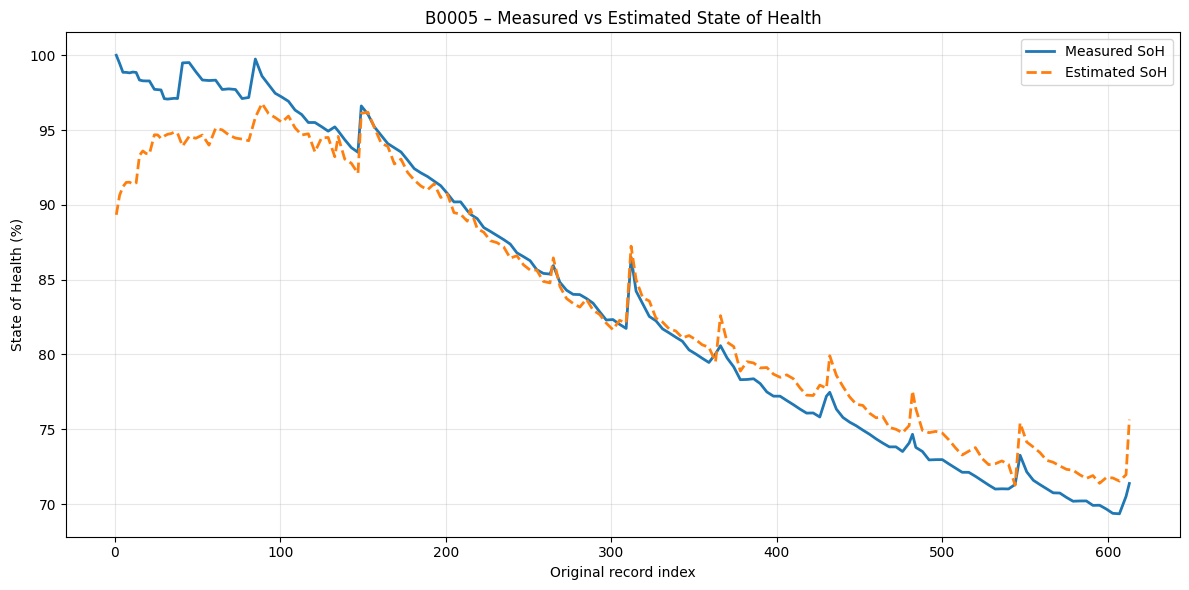

In [11]:

# Compare measured and estimated State of Health

plt.figure(figsize=(12, 6))

plt.plot(
    battery_history_df["record_index"],
    battery_history_df["measured_SoH"],
    label="Measured SoH",
    linewidth=2
)

plt.plot(
    battery_history_df["record_index"],
    battery_history_df["estimated_SoH"],
    label="Estimated SoH",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Original record index")
plt.ylabel("State of Health (%)")

plt.title(
    "B0005 – Measured vs Estimated State of Health"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:

# Step 19: Leave-One-Battery-Out validation

battery_ids = ["B0005", "B0006", "B0007", "B0018"]

lobo_results = []
lobo_predictions = {}

for test_battery in battery_ids:

    # Split training and testing data
    train_data = combined_df[
        combined_df["battery_id"] != test_battery
    ].copy()

    test_data = combined_df[
        combined_df["battery_id"] == test_battery
    ].copy()

    X_train = train_data[features_A]
    y_train = train_data["SoH_percent"]

    X_test = test_data[features_A]
    y_test = test_data["SoH_percent"]

    # Train a fresh model
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])

    model.fit(X_train, y_train)

    # Predict the held-out battery
    predictions = model.predict(X_test)

    # Evaluate performance
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    # Save predictions
    prediction_df = test_data[
        ["battery_id", "record_index", "SoH_percent"]
    ].copy()

    prediction_df["estimated_SoH"] = predictions

    lobo_predictions[test_battery] = prediction_df

    lobo_results.append({
        "battery_id": test_battery,
        "training_observations": len(train_data),
        "testing_observations": len(test_data),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Display results
lobo_results_df = pd.DataFrame(lobo_results)

display(lobo_results_df.round(4))


,battery_id,training_observations,testing_observations,MAE,RMSE,R2
0,B0005,468,168,1.7923,2.5010,0.9402
1,B0006,468,168,3.4296,4.2320,0.8825
2,B0007,468,168,4.2123,4.9917,0.6540
3,B0018,504,132,1.5000,1.7369,0.9564


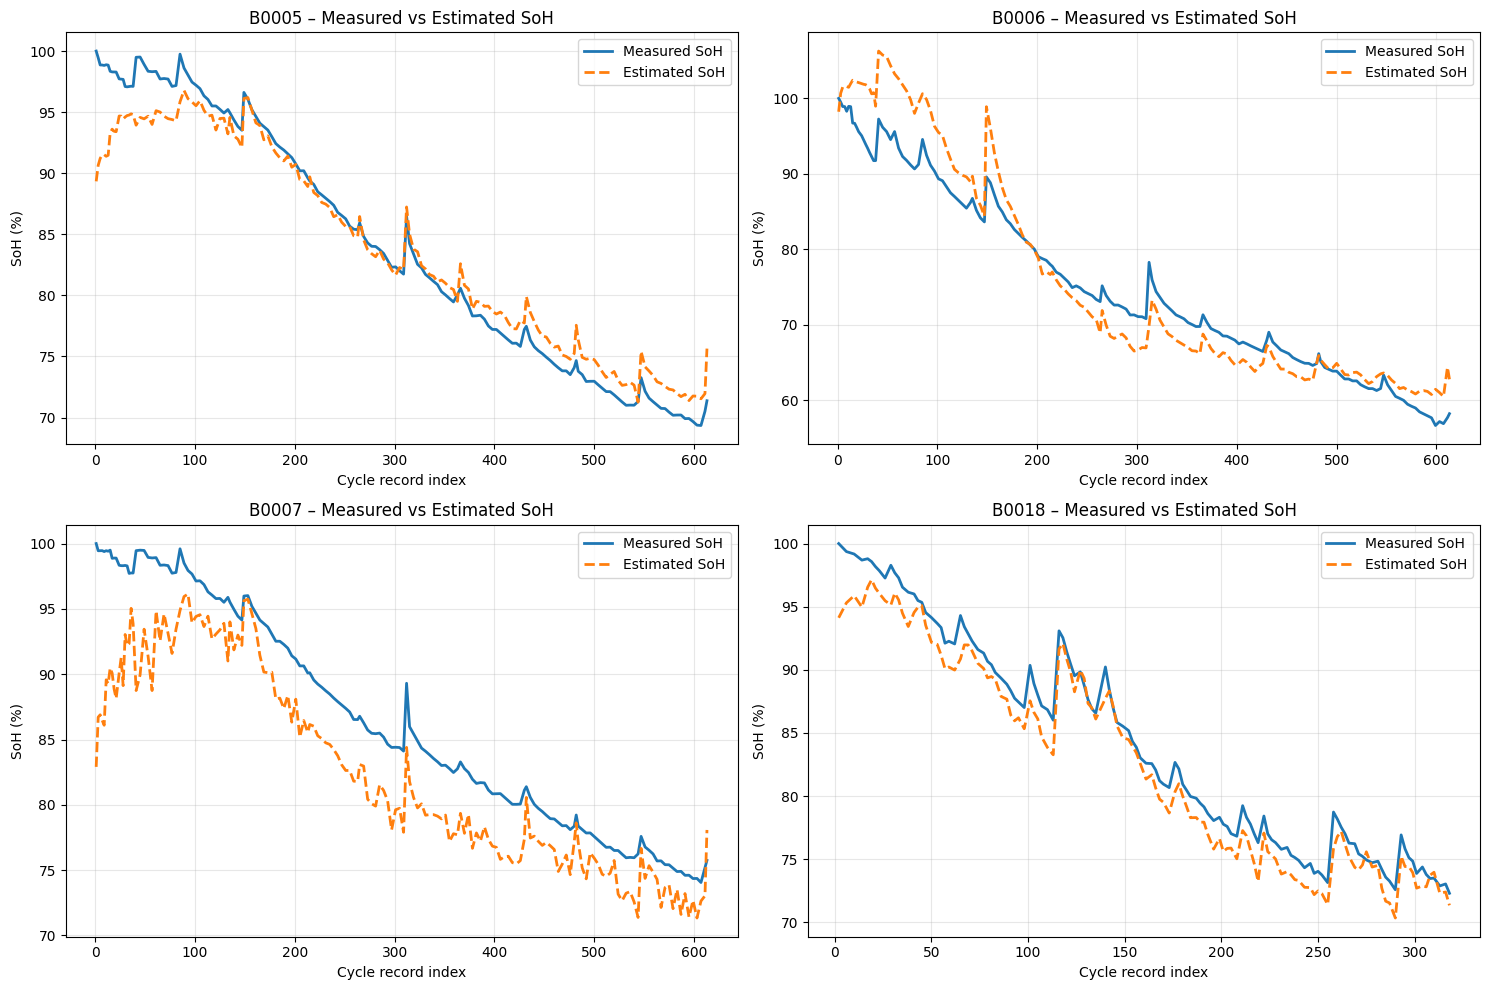

In [13]:

# Step 20: Compare measured and estimated SoH for all batteries

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for i, battery_id in enumerate(battery_ids):

    ax = axes[i // 2, i % 2]

    prediction_df = lobo_predictions[battery_id]

    ax.plot(
        prediction_df["record_index"],
        prediction_df["SoH_percent"],
        label="Measured SoH",
        linewidth=2
    )

    ax.plot(
        prediction_df["record_index"],
        prediction_df["estimated_SoH"],
        label="Estimated SoH",
        linestyle="--",
        linewidth=2
    )

    ax.set_title(f"{battery_id} – Measured vs Estimated SoH")
    ax.set_xlabel("Cycle record index")
    ax.set_ylabel("SoH (%)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


In [14]:

# Step 21: Analyse prediction errors for all batteries

error_results = []

for battery_id in battery_ids:

    prediction_df = lobo_predictions[battery_id].copy()

    prediction_df["prediction_error"] = (
        prediction_df["estimated_SoH"] -
        prediction_df["SoH_percent"]
    )

    error_results.append({
        "battery_id": battery_id,
        "mean_error": prediction_df["prediction_error"].mean(),
        "median_error": prediction_df["prediction_error"].median(),
        "MAE": prediction_df["prediction_error"].abs().mean(),
        "maximum_absolute_error": prediction_df["prediction_error"].abs().max()
    })

error_analysis_df = pd.DataFrame(error_results)

display(error_analysis_df.round(3))


,battery_id,mean_error,median_error,MAE,maximum_absolute_error
0,B0005,-0.379,-0.043,1.792,10.665
1,B0006,1.032,0.474,3.430,9.936
2,B0007,-4.185,-3.864,4.212,17.093
3,B0018,-1.466,-1.464,1.500,5.879


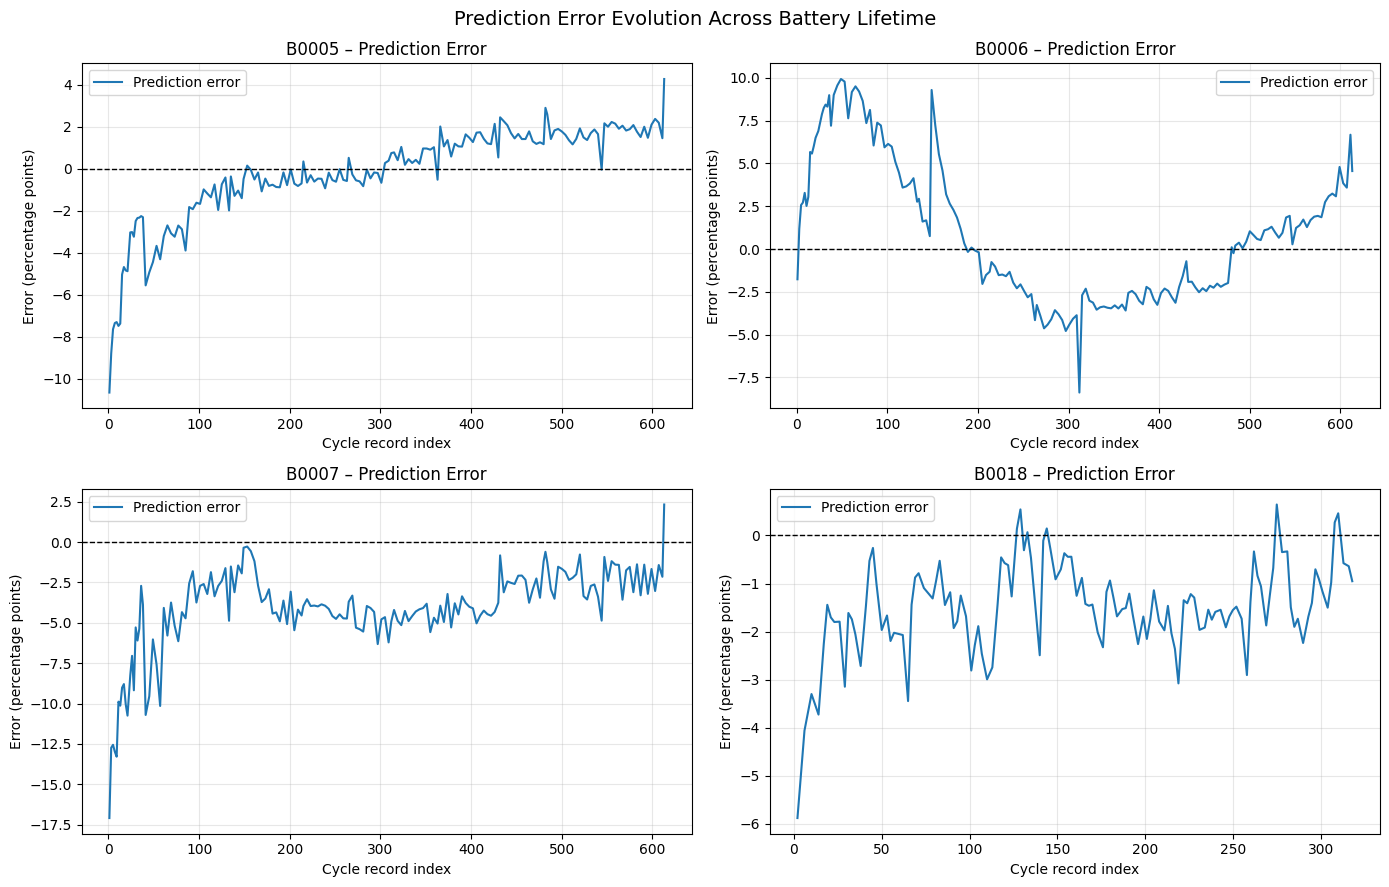

In [15]:

# Step 22: Visualise prediction errors over battery lifetime

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, battery_id in enumerate(battery_ids):

    ax = axes[i // 2, i % 2]

    prediction_df = lobo_predictions[battery_id].copy()

    prediction_error = (
        prediction_df["estimated_SoH"] -
        prediction_df["SoH_percent"]
    )

    ax.plot(
        prediction_df["record_index"],
        prediction_error,
        linewidth=1.5,
        label="Prediction error"
    )

    # Zero line: perfect prediction
    ax.axhline(
        y=0,
        linestyle="--",
        linewidth=1,
        color="black"
    )

    ax.set_title(f"{battery_id} – Prediction Error")
    ax.set_xlabel("Cycle record index")
    ax.set_ylabel("Error (percentage points)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Prediction Error Evolution Across Battery Lifetime",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [16]:

# Step 23: Evaluate errors across degradation stages

stage_results = []

for battery_id in battery_ids:

    prediction_df = (
        lobo_predictions[battery_id]
        .sort_values("record_index")
        .copy()
        .reset_index(drop=True)
    )

    # Divide observations into three chronological stages
    prediction_df["stage"] = pd.qcut(
        np.arange(len(prediction_df)),
        q=3,
        labels=["Early life", "Middle life", "Late life"]
    )

    prediction_df["error"] = (
        prediction_df["estimated_SoH"] -
        prediction_df["SoH_percent"]
    )

    for stage in ["Early life", "Middle life", "Late life"]:

        stage_data = prediction_df[
            prediction_df["stage"] == stage
        ]

        stage_results.append({
            "battery_id": battery_id,
            "stage": stage,
            "observations": len(stage_data),
            "mean_error": stage_data["error"].mean(),
            "MAE": stage_data["error"].abs().mean()
        })

stage_results_df = pd.DataFrame(stage_results)

display(stage_results_df.round(3))


,battery_id,stage,observations,mean_error,MAE
0,B0005,Early life,56,-2.978,2.984
1,B0005,Middle life,56,0.103,0.654
2,B0005,Late life,56,1.737,1.739
3,B0006,Early life,56,5.530,5.593
4,B0006,Middle life,56,-2.770,2.785
5,B0006,Late life,56,0.336,1.911
6,B0007,Early life,56,-5.610,5.610
7,B0007,Middle life,56,-4.441,4.441
8,B0007,Late life,56,-2.503,2.586
9,B0018,Early life,44,-1.950,1.950


In [17]:

# Step 24: Prepare matched observations for impedance modelling

# Keep only observations with available impedance measurements
matched_data = combined_df[
    combined_df["impedance_available"] == 1
].copy()

# Define the two feature sets
features_A = [
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "current_mean",
    "temperature_mean",
    "temperature_max",
    "temperature_rise"
]

features_B = features_A + ["Re", "Rct"]

print("Impedance-aware dataset prepared.")
print("Total matched observations:", len(matched_data))

print("\nObservations per battery:")
print(matched_data.groupby("battery_id").size())

print("\nMissing impedance values:")
print(matched_data[["Re", "Rct"]].isna().sum())


Impedance-aware dataset prepared.
Total matched observations: 419

Observations per battery:
battery_id
B0005    132
B0006    132
B0007    132
B0018     23
dtype: int64

Missing impedance values:
Re     0
Rct    0
dtype: int64


In [18]:

# Step 25: Fair comparison of Model A and Model B

results_impedance = []
impedance_predictions = {}

for test_battery in battery_ids:

    # Use the same matched observations for both models
    train_data = matched_data[
        matched_data["battery_id"] != test_battery
    ].copy()

    test_data = matched_data[
        matched_data["battery_id"] == test_battery
    ].copy()

    y_train = train_data["SoH_percent"]
    y_test = test_data["SoH_percent"]

    # Model A: Voltage, current and temperature
    model_A = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])

    model_A.fit(train_data[features_A], y_train)
    predictions_A = model_A.predict(test_data[features_A])

    # Model B: Model A features + impedance
    model_B = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])

    model_B.fit(train_data[features_B], y_train)
    predictions_B = model_B.predict(test_data[features_B])

    # Evaluate both models
    for model_name, predictions in [
        ("Model A", predictions_A),
        ("Model B", predictions_B)
    ]:

        results_impedance.append({
            "battery_id": test_battery,
            "model": model_name,
            "training_observations": len(train_data),
            "testing_observations": len(test_data),
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "R2": r2_score(y_test, predictions)
        })

    # Store predictions for later visualisation
    prediction_df = test_data[
        ["battery_id", "record_index", "SoH_percent"]
    ].copy()

    prediction_df["Model_A_estimated_SoH"] = predictions_A
    prediction_df["Model_B_estimated_SoH"] = predictions_B

    impedance_predictions[test_battery] = prediction_df


# Display comparison
impedance_results_df = pd.DataFrame(results_impedance)

display(
    impedance_results_df.round(4)
)


,battery_id,model,training_observations,testing_observations,MAE,RMSE,R2
0,B0005,Model A,287,132,1.4376,1.9930,0.9569
1,B0005,Model B,287,132,1.7044,2.0615,0.9539
2,B0006,Model A,287,132,2.9777,3.9432,0.8630
3,B0006,Model B,287,132,2.8362,3.6431,0.8831
4,B0007,Model A,287,132,3.6999,4.4348,0.6790
5,B0007,Model B,287,132,1.3230,1.7468,0.9502
6,B0018,Model A,396,23,2.5204,3.0047,0.9039
7,B0018,Model B,396,23,4.1715,5.2144,0.7105


In [19]:

# Step 26: Calculate overall model performance

overall_impedance_results = []

for model_name in ["Model A", "Model B"]:

    model_results = impedance_results_df[
        impedance_results_df["model"] == model_name
    ]

    total_observations = model_results[
        "testing_observations"
    ].sum()

    weighted_mae = np.average(
        model_results["MAE"],
        weights=model_results["testing_observations"]
    )

    weighted_rmse = np.sqrt(
        np.average(
            model_results["RMSE"] ** 2,
            weights=model_results["testing_observations"]
        )
    )

    overall_impedance_results.append({
        "model": model_name,
        "total_test_observations": total_observations,
        "weighted_MAE": weighted_mae,
        "weighted_RMSE": weighted_rmse
    })

overall_impedance_df = pd.DataFrame(
    overall_impedance_results
)

display(overall_impedance_df.round(4))

# Calculate percentage improvement
mae_A = overall_impedance_df.loc[
    overall_impedance_df["model"] == "Model A",
    "weighted_MAE"
].iloc[0]

mae_B = overall_impedance_df.loc[
    overall_impedance_df["model"] == "Model B",
    "weighted_MAE"
].iloc[0]

improvement = ((mae_A - mae_B) / mae_A) * 100

print("Weighted MAE improvement:", round(improvement, 2), "%")


,model,total_test_observations,weighted_MAE,weighted_RMSE
0,Model A,419,2.6949,3.5835
1,Model B,419,2.0762,2.8238


Weighted MAE improvement: 22.96 %


In [20]:

# Step 27: Build and validate the hybrid SoH estimator

hybrid_predictions = {}
hybrid_results = []

for test_battery in battery_ids:

    # Training data: matched observations from the other batteries
    train_data = matched_data[
        matched_data["battery_id"] != test_battery
    ].copy()

    # Test data: ALL observations from the held-out battery
    test_data = combined_df[
        combined_df["battery_id"] == test_battery
    ].copy()

    test_data = test_data.sort_values("record_index").copy()

    y_train = train_data["SoH_percent"]

    # Model A: trained on matched data, usable without impedance
    model_A = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])

    model_A.fit(train_data[features_A], y_train)

    predictions_A = model_A.predict(test_data[features_A])

    # Model B: used only when impedance is available
    model_B = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])

    model_B.fit(train_data[features_B], y_train)

    # Start with Model A predictions
    test_data["estimated_SoH"] = predictions_A
    test_data["selected_model"] = "Model A"

    # Replace with Model B predictions where impedance exists
    impedance_mask = test_data["impedance_available"] == 1

    if impedance_mask.any():

        predictions_B = model_B.predict(
            test_data.loc[impedance_mask, features_B]
        )

        test_data.loc[
            impedance_mask, "estimated_SoH"
        ] = predictions_B

        test_data.loc[
            impedance_mask, "selected_model"
        ] = "Model B"

    # Store reference and estimated health
    hybrid_predictions[test_battery] = test_data[
        [
            "battery_id",
            "record_index",
            "SoH_percent",
            "estimated_SoH",
            "impedance_available",
            "selected_model"
        ]
    ].copy()

    # Evaluate the complete hybrid prediction
    mae = mean_absolute_error(
        test_data["SoH_percent"],
        test_data["estimated_SoH"]
    )

    rmse = np.sqrt(mean_squared_error(
        test_data["SoH_percent"],
        test_data["estimated_SoH"]
    ))

    r2 = r2_score(
        test_data["SoH_percent"],
        test_data["estimated_SoH"]
    )

    hybrid_results.append({
        "battery_id": test_battery,
        "observations": len(test_data),
        "Model_A_used": (test_data["selected_model"] == "Model A").sum(),
        "Model_B_used": (test_data["selected_model"] == "Model B").sum(),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

hybrid_results_df = pd.DataFrame(hybrid_results)

print("Hybrid estimator completed.")
display(hybrid_results_df.round(4))


Hybrid estimator completed.


,battery_id,observations,Model_A_used,Model_B_used,MAE,RMSE,R2
0,B0005,168,36,132,2.2762,3.1627,0.9043
1,B0006,168,36,132,3.1331,4.0313,0.8934
2,B0007,168,36,132,2.6991,4.6620,0.6982
3,B0018,132,109,23,2.0739,2.8106,0.8858


In [21]:
# Step 28: Compare Model A-only against the Hybrid Estimator

comparison_results = []

for test_battery in battery_ids:

    # Same training observations used in Step 27
    train_data = matched_data[
        matched_data["battery_id"] != test_battery
    ].copy()

    # All observations of the held-out battery
    test_data = combined_df[
        combined_df["battery_id"] == test_battery
    ].copy()

    test_data = test_data.sort_values("record_index").copy()

    y_train = train_data["SoH_percent"]
    y_test = test_data["SoH_percent"]

    # -----------------------------
    # Model A: no impedance features
    # -----------------------------

    model_A = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])

    model_A.fit(train_data[features_A], y_train)

    predictions_A = model_A.predict(
        test_data[features_A]
    )

    # -----------------------------
    # Model B: with impedance features
    # -----------------------------

    model_B = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])

    model_B.fit(train_data[features_B], y_train)

    # Start hybrid predictions with Model A
    hybrid_predictions_current = predictions_A.copy()

    impedance_mask = (
        test_data["impedance_available"] == 1
    )

    # Replace predictions where impedance is available
    if impedance_mask.any():

        predictions_B = model_B.predict(
            test_data.loc[impedance_mask, features_B]
        )

        hybrid_predictions_current[impedance_mask.values] = (
            predictions_B
        )

    # Calculate baseline metrics
    mae_A = mean_absolute_error(
        y_test, predictions_A
    )

    rmse_A = np.sqrt(
        mean_squared_error(y_test, predictions_A)
    )

    # Calculate hybrid metrics
    mae_hybrid = mean_absolute_error(
        y_test, hybrid_predictions_current
    )

    rmse_hybrid = np.sqrt(
        mean_squared_error(y_test, hybrid_predictions_current)
    )

    comparison_results.append({
        "battery_id": test_battery,
        "Model_A_MAE": mae_A,
        "Hybrid_MAE": mae_hybrid,
        "MAE_improvement_percent": (
            (mae_A - mae_hybrid) / mae_A * 100
        ),
        "Model_A_RMSE": rmse_A,
        "Hybrid_RMSE": rmse_hybrid
    })

comparison_df = pd.DataFrame(comparison_results)

print("Model A vs Hybrid comparison completed.")

display(comparison_df.round(4))

# Overall weighted MAE
total_observations = combined_df.shape[0]

overall_A_MAE = (
    comparison_df["Model_A_MAE"] *
    comparison_df["battery_id"].map(
        combined_df.groupby("battery_id").size()
    )
).sum() / total_observations

overall_hybrid_MAE = (
    comparison_df["Hybrid_MAE"] *
    comparison_df["battery_id"].map(
        combined_df.groupby("battery_id").size()
    )
).sum() / total_observations

print(f"Overall Model A MAE: {overall_A_MAE:.4f}%")
print(f"Overall Hybrid MAE: {overall_hybrid_MAE:.4f}%")

print(
    "Overall MAE improvement: "
    f"{(overall_A_MAE - overall_hybrid_MAE) / overall_A_MAE * 100:.2f}%"
)

Model A vs Hybrid comparison completed.


,battery_id,Model_A_MAE,Hybrid_MAE,MAE_improvement_percent,Model_A_RMSE,Hybrid_RMSE
0,B0005,2.0666,2.2762,-10.1433,3.1280,3.1627
1,B0006,3.2443,3.1331,3.4270,4.2473,4.0313
2,B0007,4.5667,2.6991,40.8952,5.8983,4.6620
3,B0018,1.7862,2.0739,-16.1067,2.1760,2.8106


Overall Model A MAE: 2.9799%
Overall Hybrid MAE: 2.5723%
Overall MAE improvement: 13.68%


In [22]:
# Step 29: Analyse the contribution of impedance per battery

impedance_analysis = []

for test_battery in battery_ids:

    # Use the same matched training data as before
    train_data = matched_data[
        matched_data["battery_id"] != test_battery
    ].copy()

    # All test observations for the held-out battery
    test_data = combined_df[
        combined_df["battery_id"] == test_battery
    ].copy()

    test_data = test_data.sort_values("record_index").copy()

    y_train = train_data["SoH_percent"]

    # Train Model A
    model_A = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])

    model_A.fit(train_data[features_A], y_train)

    # Train Model B
    model_B = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=1.0))
    ])

    model_B.fit(train_data[features_B], y_train)

    # Separate test observations by impedance availability
    matched_test = test_data[
        test_data["impedance_available"] == 1
    ].copy()

    unmatched_test = test_data[
        test_data["impedance_available"] == 0
    ].copy()

    # Compare both models on matched observations
    predictions_A_matched = model_A.predict(
        matched_test[features_A]
    )

    predictions_B_matched = model_B.predict(
        matched_test[features_B]
    )

    y_matched = matched_test["SoH_percent"]

    mae_A_matched = mean_absolute_error(
        y_matched, predictions_A_matched
    )

    mae_B_matched = mean_absolute_error(
        y_matched, predictions_B_matched
    )

    # Evaluate fallback Model A on unmatched observations
    predictions_A_unmatched = model_A.predict(
        unmatched_test[features_A]
    )

    y_unmatched = unmatched_test["SoH_percent"]

    mae_A_unmatched = mean_absolute_error(
        y_unmatched, predictions_A_unmatched
    )

    # Calculate the improvement from adding impedance
    improvement = (
        (mae_A_matched - mae_B_matched)
        / mae_A_matched * 100
    )

    impedance_analysis.append({
        "battery_id": test_battery,
        "matched_cycles": len(matched_test),
        "unmatched_cycles": len(unmatched_test),
        "Model_A_MAE_matched": mae_A_matched,
        "Model_B_MAE_matched": mae_B_matched,
        "Impedance_improvement_percent": improvement,
        "Fallback_Model_A_MAE": mae_A_unmatched
    })

impedance_analysis_df = pd.DataFrame(impedance_analysis)

print("Impedance contribution analysis completed.")

display(impedance_analysis_df.round(4))

Impedance contribution analysis completed.


,battery_id,matched_cycles,unmatched_cycles,Model_A_MAE_matched,Model_B_MAE_matched,Impedance_improvement_percent,Fallback_Model_A_MAE
0,B0005,132,36,1.4376,1.7044,-18.5580,4.3728
1,B0006,132,36,2.9777,2.8362,4.7522,4.2219
2,B0007,132,36,3.6999,1.3230,64.2425,7.7450
3,B0018,23,109,2.5204,4.1715,-65.5123,1.6313


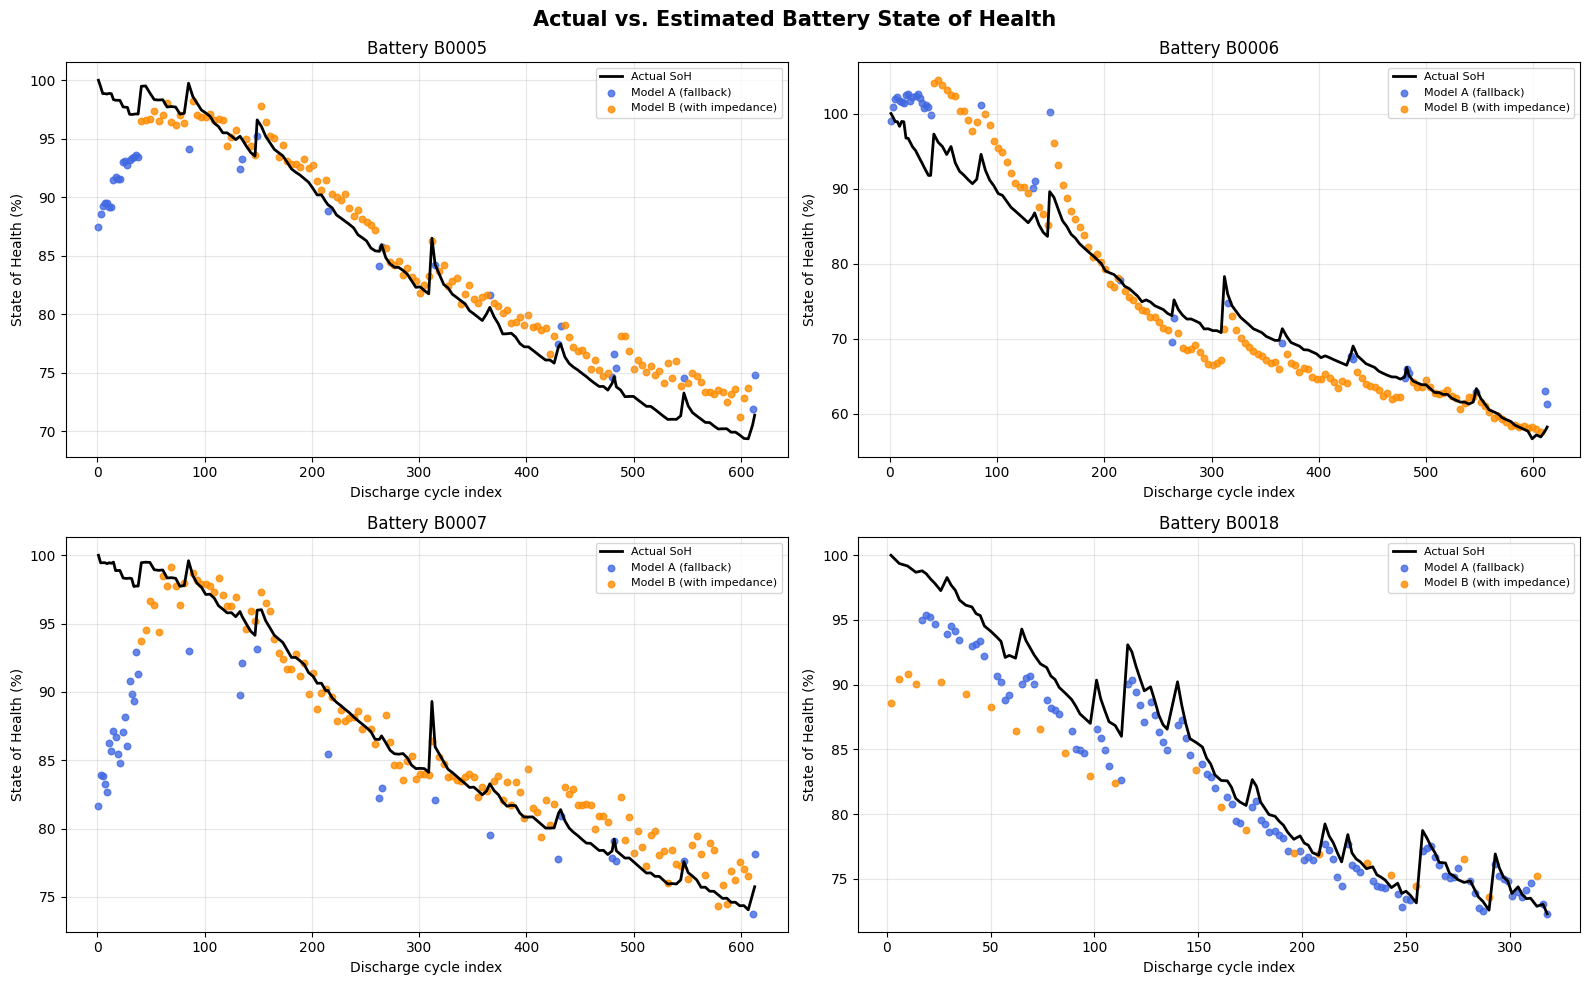

Figure saved to: /content/drive/MyDrive/Battery_Digital_Twin/results/hybrid_soh_validation.png


In [23]:
# Step 30: Visual validation of the hybrid SoH estimator

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

axes = axes.flatten()

for i, battery_id in enumerate(battery_ids):

    ax = axes[i]

    # Retrieve hybrid predictions from Step 27
    results = hybrid_predictions[battery_id].copy()

    results = results.sort_values("record_index")

    # Actual SoH
    ax.plot(
        results["record_index"],
        results["SoH_percent"],
        color="black",
        linewidth=2,
        label="Actual SoH"
    )

    # Model A predictions: impedance unavailable
    model_A_data = results[
        results["selected_model"] == "Model A"
    ]

    ax.scatter(
        model_A_data["record_index"],
        model_A_data["estimated_SoH"],
        color="royalblue",
        s=22,
        alpha=0.8,
        label="Model A (fallback)"
    )

    # Model B predictions: impedance available
    model_B_data = results[
        results["selected_model"] == "Model B"
    ]

    ax.scatter(
        model_B_data["record_index"],
        model_B_data["estimated_SoH"],
        color="darkorange",
        s=22,
        alpha=0.8,
        label="Model B (with impedance)"
    )

    ax.set_title(f"Battery {battery_id}")
    ax.set_xlabel("Discharge cycle index")
    ax.set_ylabel("State of Health (%)")

    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(
    "Actual vs. Estimated Battery State of Health",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

# Save the figure
figure_path = os.path.join(
    results_folder,
    "hybrid_soh_validation.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)

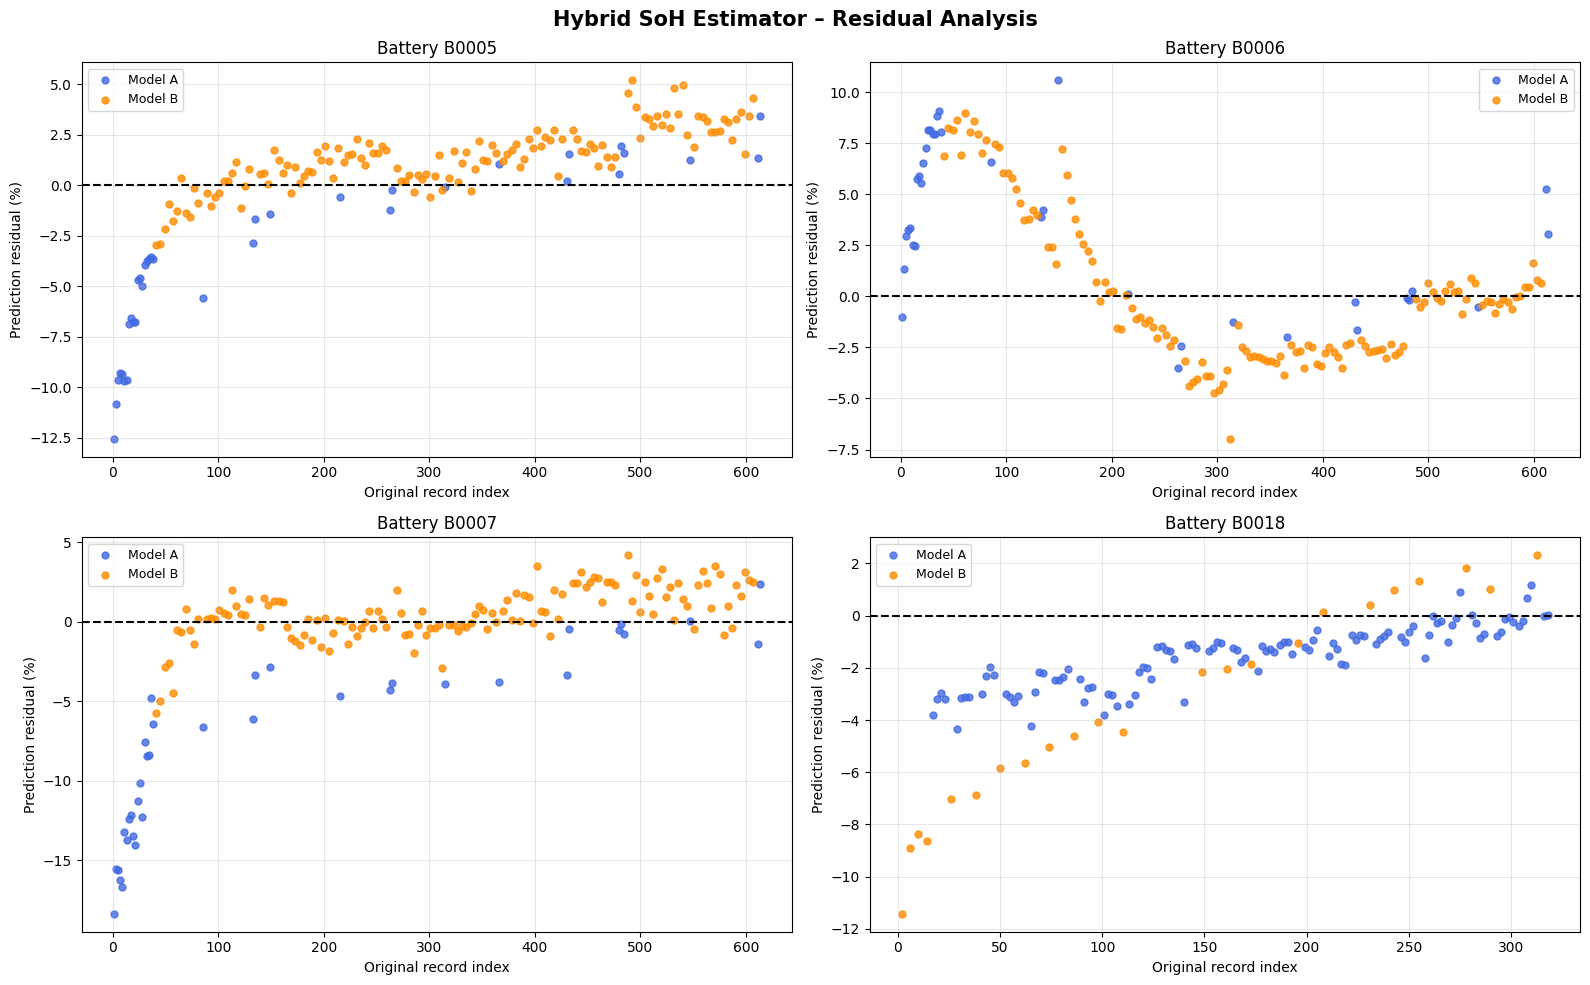

Residual figure saved to: /content/drive/MyDrive/Battery_Digital_Twin/results/hybrid_soh_residuals.png


In [24]:
# Step 31: Residual analysis of the hybrid estimator

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, battery_id in enumerate(battery_ids):

    ax = axes[i]

    results = hybrid_predictions[battery_id].copy()
    results = results.sort_values("record_index")

    results["residual"] = (
        results["estimated_SoH"] - results["SoH_percent"]
    )

    # Model A residuals
    model_A_data = results[
        results["selected_model"] == "Model A"
    ]

    ax.scatter(
        model_A_data["record_index"],
        model_A_data["residual"],
        color="royalblue",
        s=25,
        alpha=0.8,
        label="Model A"
    )

    # Model B residuals
    model_B_data = results[
        results["selected_model"] == "Model B"
    ]

    ax.scatter(
        model_B_data["record_index"],
        model_B_data["residual"],
        color="darkorange",
        s=25,
        alpha=0.8,
        label="Model B"
    )

    # Zero-error reference
    ax.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=1.5
    )

    ax.set_title(f"Battery {battery_id}")
    ax.set_xlabel("Original record index")
    ax.set_ylabel("Prediction residual (%)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

plt.suptitle(
    "Hybrid SoH Estimator – Residual Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

residual_path = os.path.join(
    results_folder,
    "hybrid_soh_residuals.png"
)

plt.savefig(
    residual_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Residual figure saved to:", residual_path)

In [25]:
# Step 32: Quantitative residual analysis by battery and model

residual_summary = []

for battery_id in battery_ids:

    results = hybrid_predictions[battery_id].copy()

    results["residual"] = (
        results["estimated_SoH"] - results["SoH_percent"]
    )

    for model_name in ["Model A", "Model B"]:

        model_data = results[
            results["selected_model"] == model_name
        ].copy()

        if len(model_data) == 0:
            continue

        residual_summary.append({

            "battery_id": battery_id,

            "model": model_name,

            "observations": len(model_data),

            "mean_residual": model_data["residual"].mean(),

            "median_residual": model_data["residual"].median(),

            "MAE": model_data["residual"].abs().mean(),

            "RMSE": np.sqrt(
                (model_data["residual"] ** 2).mean()
            ),

            "residual_std": model_data["residual"].std()

        })

residual_summary_df = pd.DataFrame(residual_summary)

print("Residual statistics by battery and model:")

display(residual_summary_df.round(4))

Residual statistics by battery and model:


,battery_id,model,observations,mean_residual,median_residual,MAE,RMSE,residual_std
0,B0005,Model A,36,-3.6492,-3.6412,4.3728,5.5764,4.2765
1,B0005,Model B,132,1.3821,1.4541,1.7044,2.0615,1.5354
2,B0006,Model A,36,3.5066,3.2876,4.2219,5.2129,3.9119
3,B0006,Model B,132,0.0809,-0.5626,2.8362,3.6431,3.6561
4,B0007,Model A,36,-7.6098,-6.4892,7.7450,9.4994,5.7666
5,B0007,Model B,132,0.5567,0.4991,1.3230,1.7468,1.6621
6,B0018,Model A,109,-1.5799,-1.3120,1.6313,1.9569,1.1599
7,B0018,Model B,23,-3.4738,-4.0644,4.1715,5.2144,3.9762


In [26]:
# Step 33: Export model evaluation results

# Save hybrid comparison
comparison_df.to_csv(
    os.path.join(results_folder, "model_A_vs_hybrid.csv"),
    index=False
)

# Save impedance contribution analysis
impedance_analysis_df.to_csv(
    os.path.join(results_folder, "impedance_contribution_analysis.csv"),
    index=False
)

# Save residual statistics
residual_summary_df.to_csv(
    os.path.join(results_folder, "residual_statistics.csv"),
    index=False
)

# Save hybrid predictions for all batteries
all_hybrid_predictions = pd.concat(
    hybrid_predictions.values(),
    ignore_index=True
)

all_hybrid_predictions.to_csv(
    os.path.join(results_folder, "hybrid_predictions.csv"),
    index=False
)

print("Evaluation results successfully exported.")

print("\nFiles saved:")
print("1. model_A_vs_hybrid.csv")
print("2. impedance_contribution_analysis.csv")
print("3. residual_statistics.csv")
print("4. hybrid_predictions.csv")

Evaluation results successfully exported.

Files saved:
1. model_A_vs_hybrid.csv
2. impedance_contribution_analysis.csv
3. residual_statistics.csv
4. hybrid_predictions.csv


In [27]:
# Step 34: Verify project output files

print("Project results folder:")
print(results_folder)

print("\nFiles available:")

for filename in sorted(os.listdir(results_folder)):
    filepath = os.path.join(results_folder, filename)

    if os.path.isfile(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"{filename} — {size_kb:.2f} KB")

Project results folder:
/content/drive/MyDrive/Battery_Digital_Twin/results

Files available:
apparent_RC_parameters.csv — 262.59 KB
combined_battery_dataset.csv — 182.45 KB
combined_dataset_with_relaxation.csv — 231.01 KB
cycle_Re_correlations.csv — 0.17 KB
full_data_coefficients.csv — 0.31 KB
hybrid_predictions.csv — 36.57 KB
hybrid_soh_residuals.png — 684.09 KB
hybrid_soh_validation.png — 959.51 KB
impedance_contribution_analysis.csv — 0.47 KB
lobo_relaxation_model_comparison.csv — 1.64 KB
lobo_relaxation_overall_results.csv — 0.39 KB
model_A_vs_hybrid.csv — 0.47 KB
modelling_summary.md — 2.67 KB
multicollinearity_VIF.csv — 0.20 KB
overall_model_performance.csv — 0.28 KB
relaxation_parameters_all_batteries.csv — 56.16 KB
relaxation_soh_correlations_all_batteries.csv — 0.97 KB
residual_Re_comparison.csv — 0.25 KB
residual_statistics.csv — 0.95 KB
revised_apparent_resistance.csv — 95.44 KB
revised_resistance_correlations.csv — 0.43 KB
revised_resistance_model_comparison.csv — 0.58 KB


In [28]:
# Step 35: Read the existing modelling summary

summary_path = os.path.join(
    results_folder,
    "modelling_summary.md"
)

with open(summary_path, "r", encoding="utf-8") as file:
    modelling_summary = file.read()

print(modelling_summary)


# Battery Digital Twin – Modelling Results

## 1. Dataset
- NASA Battery Aging Dataset
- Batteries: B0005, B0006, B0007, B0018
- Total discharge observations: 636
- Matched impedance observations: 419
- Health target: State of Health (SoH), calculated from
  discharge capacity relative to initial measured capacity.

## 2. Modelling objective
Investigate whether electrical and thermal indicators,
particularly impedance resistance (Re), provide useful
information for battery SoH estimation.

## 3. Temporal validation
A chronological 70/30 train-test split was used for
each battery.

| Model | Weighted MAE | Weighted RMSE |
|---|---:|---:|
| Cycle + Re | 3.0894 | 3.3447 |
| Cycle only | 3.6955 | 4.0590 |
| Polynomial | 4.2225 | 6.0997 |

Cycle + Re achieved a 16.4% reduction in weighted MAE
compared with Cycle only.

## 4. Multicollinearity
Training-set correlations between cycle number and Re:
- B0005: 0.9629
- B0006: 0.9851
- B0007: 0.9391
- B0018: 0.2091

VIF values:
- B0005: 13.74
- 

In [29]:
# Step 36: Update modelling summary with hybrid results

hybrid_documentation = """

## 9. Matched-Observation Model Comparison

A leave-one-battery-out (LOBO) comparison was conducted
using the 419 observations with available impedance data.

Both models were trained on the same matched training
observations. Model A used electrical and thermal features,
while Model B additionally included Re and Rct.

| Model | Weighted MAE | Weighted RMSE |
|---|---:|---:|
| Model A | 2.6949 | 3.5835 |
| Model B | 2.0762 | 2.8238 |

Model B achieved a 22.96% reduction in weighted MAE.

However, the improvement varied across batteries,
indicating that impedance indicators do not provide
a uniform benefit.

## 10. Hybrid SoH Estimator

A hybrid estimation architecture was implemented to
handle incomplete impedance measurements.

- Model A: electrical and thermal features; used as fallback.
- Model B: electrical, thermal and impedance features;
  used when impedance measurements are available.

The estimator was evaluated using leave-one-battery-out
validation across all 636 discharge observations.

| Battery | Observations | Model A | Model B | MAE |
|---|---:|---:|---:|---:|
| B0005 | 168 | 36 | 132 | 2.2762 |
| B0006 | 168 | 36 | 132 | 3.1331 |
| B0007 | 168 | 36 | 132 | 2.6991 |
| B0018 | 132 | 109 | 23 | 2.0739 |

The overall comparison was:

| Model | Overall MAE |
|---|---:|
| Model A only | 2.9799 |
| Hybrid estimator | 2.5723 |

The hybrid estimator achieved a 13.68% reduction
in overall MAE.

## 11. Impedance Contribution Analysis

A separate comparison evaluated Model A and Model B
on identical impedance-matched test observations.

| Battery | Model A MAE | Model B MAE | Improvement |
|---|---:|---:|---:|
| B0005 | 1.4376 | 1.7044 | -18.56% |
| B0006 | 2.9777 | 2.8362 | 4.75% |
| B0007 | 3.6999 | 1.3230 | 64.24% |
| B0018 | 2.5204 | 4.1715 | -65.51% |

Impedance features substantially improved performance
for B0007, provided a modest improvement for B0006,
and deteriorated performance for B0005 and B0018.

These findings demonstrate battery-dependent predictive
value of impedance indicators.

## 12. Residual Analysis

Residuals were calculated as:

Estimated SoH minus Actual SoH.

Positive residuals indicate overestimation, while
negative residuals indicate underestimation.

The analysis identified:

- B0005: positive bias in Model B predictions.
- B0006: near-zero mean residual for Model B.
- B0007: substantially reduced underestimation with Model B.
- B0018: stronger negative bias for Model B.

The residual distributions also showed systematic
changes over the battery lifecycle.

This suggests that the current linear Ridge regression
models do not fully capture the degradation dynamics.

## 13. Updated Conclusions

The experiments indicate that:

- Electrical and thermal measurements provide a useful
  baseline for cycle-level SoH estimation.
- Impedance indicators can improve estimation accuracy,
  but their contribution varies between batteries.
- The hybrid architecture provides a practical approach
  to handling missing impedance observations.
- The hybrid estimator achieved a 13.68% overall MAE
  improvement relative to the matched-trained Model A baseline.
- Systematic residual patterns indicate that further
  model development and validation are necessary.

The current implementation is an offline, historical
battery health-monitoring prototype. It is not yet a
real-time connected Digital Twin.

"""

with open(summary_path, "a", encoding="utf-8") as file:
    file.write(hybrid_documentation)

print("Modelling summary successfully updated.")
print("Updated file:", summary_path)

Modelling summary successfully updated.
Updated file: /content/drive/MyDrive/Battery_Digital_Twin/results/modelling_summary.md


In [30]:
import os

project_folder = "/content/drive/MyDrive/Battery_Digital_Twin"

print("Files and folders inside the project:\n")

for root, dirs, files in os.walk(project_folder):
    level = root.replace(project_folder, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        if file.endswith(".mat") or file.endswith(".zip"):
            print(f"{indent}    {file}")

Files and folders inside the project:

Battery_Digital_Twin/
    results/
    notebooks/
    raw_data/
        B0005.mat
        B0018.mat
        B0006.mat
        B0007.mat
    github_ready/
        notebooks/
    data/
        B0005.mat
        B0007.mat
        B0006.mat
        B0018.mat


In [31]:
import os

drive_folder = "/content/drive/MyDrive"

target_files = {
    "B0005.mat",
    "B0006.mat",
    "B0007.mat",
    "B0018.mat"
}

print("Searching Google Drive...\n")

for root, dirs, files in os.walk(drive_folder):
    for file in files:
        if file in target_files:
            print(os.path.join(root, file))

Searching Google Drive...

/content/drive/MyDrive/Battery_Digital_Twin/raw_data/B0005.mat
/content/drive/MyDrive/Battery_Digital_Twin/raw_data/B0018.mat
/content/drive/MyDrive/Battery_Digital_Twin/raw_data/B0006.mat
/content/drive/MyDrive/Battery_Digital_Twin/raw_data/B0007.mat
/content/drive/MyDrive/Battery_Digital_Twin/data/B0005.mat
/content/drive/MyDrive/Battery_Digital_Twin/data/B0007.mat
/content/drive/MyDrive/Battery_Digital_Twin/data/B0006.mat
/content/drive/MyDrive/Battery_Digital_Twin/data/B0018.mat


In [32]:
import os

search_locations = [
    "/content",
    "/content/drive/Shareddrives"
]

target_files = {
    "B0005.mat",
    "B0006.mat",
    "B0007.mat",
    "B0018.mat"
}

for location in search_locations:
    if not os.path.exists(location):
        continue

    print(f"\nSearching: {location}")

    for root, dirs, files in os.walk(location):
        # Avoid searching Google Drive again
        if root.startswith("/content/drive/MyDrive"):
            dirs[:] = []
            continue

        for file in files:
            if file in target_files or file.endswith(".zip"):
                print(os.path.join(root, file))


Searching: /content


In [33]:
# Step 42: Inspect raw battery measurements

from scipy.io import loadmat
import numpy as np
import os

battery_file = os.path.join(
    project_folder,
    "raw_data",
    "B0005.mat"
)

mat_data = loadmat(
    battery_file,
    squeeze_me=True,
    struct_as_record=False
)

battery = mat_data["B0005"]
cycles = np.atleast_1d(battery.cycle)

print("Total records:", len(cycles))

for operation in ["charge", "discharge", "impedance"]:

    matching_cycles = [
        cycle for cycle in cycles
        if str(cycle.type).lower() == operation
    ]

    print(f"\n{operation.upper()} records:", len(matching_cycles))

    if matching_cycles:

        sample = matching_cycles[0]

        print("Measurement fields:")

        for field in sample.data._fieldnames:

            value = getattr(sample.data, field)

            if isinstance(value, np.ndarray):
                print(f"  {field}: shape {value.shape}")

            else:
                print(f"  {field}: {type(value).__name__}")

Total records: 616

CHARGE records: 170
Measurement fields:
  Voltage_measured: shape (789,)
  Current_measured: shape (789,)
  Temperature_measured: shape (789,)
  Current_charge: shape (789,)
  Voltage_charge: shape (789,)
  Time: shape (789,)

DISCHARGE records: 168
Measurement fields:
  Voltage_measured: shape (197,)
  Current_measured: shape (197,)
  Temperature_measured: shape (197,)
  Current_load: shape (197,)
  Voltage_load: shape (197,)
  Time: shape (197,)
  Capacity: float

IMPEDANCE records: 278
Measurement fields:
  Sense_current: shape (48,)
  Battery_current: shape (48,)
  Current_ratio: shape (48,)
  Battery_impedance: shape (48,)
  Rectified_Impedance: shape (39,)
  Re: float
  Rct: float


CHARGE PROFILE
-------------------------
Current minimum: -4.030268477538787
Current maximum: 1.5143932321982565
Current standard deviation: 0.6254070302865201
Voltage minimum: 3.479393559379272
Voltage maximum: 4.2099486995035615
Duration (seconds): 7597.875

DISCHARGE PROFILE
-------------------------
Current minimum: -2.0180146876333027
Current maximum: 0.000728585272845447
Current standard deviation: 0.593546181674474
Voltage minimum: 2.612467347907089
Voltage maximum: 4.191491807505295
Duration (seconds): 3690.234


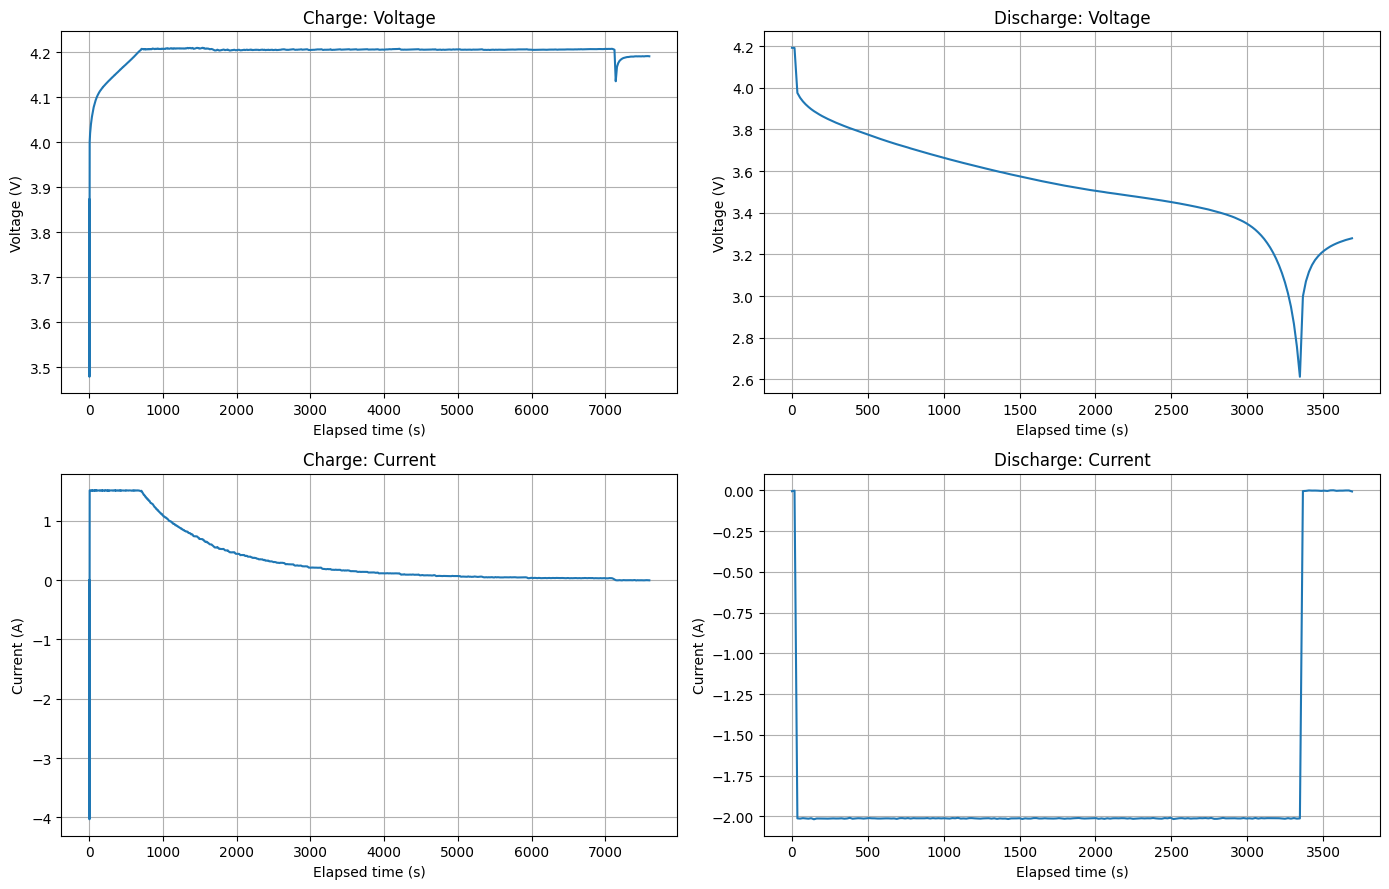

In [34]:
# Step 43: Visual inspection of charge and discharge dynamics

import numpy as np
import matplotlib.pyplot as plt

# Select the first charge and discharge records
charge_record = next(
    cycle for cycle in cycles
    if str(cycle.type).lower() == "charge"
)

discharge_record = next(
    cycle for cycle in cycles
    if str(cycle.type).lower() == "discharge"
)

# Extract measurements
charge_data = charge_record.data
discharge_data = discharge_record.data

charge_time = np.asarray(
    charge_data.Time, dtype=float
).flatten()

charge_voltage = np.asarray(
    charge_data.Voltage_measured, dtype=float
).flatten()

charge_current = np.asarray(
    charge_data.Current_measured, dtype=float
).flatten()

discharge_time = np.asarray(
    discharge_data.Time, dtype=float
).flatten()

discharge_voltage = np.asarray(
    discharge_data.Voltage_measured, dtype=float
).flatten()

discharge_current = np.asarray(
    discharge_data.Current_measured, dtype=float
).flatten()

# Convert time to elapsed seconds
charge_time = charge_time - charge_time[0]
discharge_time = discharge_time - discharge_time[0]

# Print current and time statistics
print("CHARGE PROFILE")
print("-------------------------")
print("Current minimum:", np.min(charge_current))
print("Current maximum:", np.max(charge_current))
print("Current standard deviation:", np.std(charge_current))
print("Voltage minimum:", np.min(charge_voltage))
print("Voltage maximum:", np.max(charge_voltage))
print("Duration (seconds):", charge_time[-1])

print("\nDISCHARGE PROFILE")
print("-------------------------")
print("Current minimum:", np.min(discharge_current))
print("Current maximum:", np.max(discharge_current))
print("Current standard deviation:", np.std(discharge_current))
print("Voltage minimum:", np.min(discharge_voltage))
print("Voltage maximum:", np.max(discharge_voltage))
print("Duration (seconds):", discharge_time[-1])

# Plot charge and discharge profiles
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(charge_time, charge_voltage)
axes[0, 0].set_title("Charge: Voltage")
axes[0, 0].set_xlabel("Elapsed time (s)")
axes[0, 0].set_ylabel("Voltage (V)")
axes[0, 0].grid(True)

axes[1, 0].plot(charge_time, charge_current)
axes[1, 0].set_title("Charge: Current")
axes[1, 0].set_xlabel("Elapsed time (s)")
axes[1, 0].set_ylabel("Current (A)")
axes[1, 0].grid(True)

axes[0, 1].plot(discharge_time, discharge_voltage)
axes[0, 1].set_title("Discharge: Voltage")
axes[0, 1].set_xlabel("Elapsed time (s)")
axes[0, 1].set_ylabel("Voltage (V)")
axes[0, 1].grid(True)

axes[1, 1].plot(discharge_time, discharge_current)
axes[1, 1].set_title("Discharge: Current")
axes[1, 1].set_xlabel("Elapsed time (s)")
axes[1, 1].set_ylabel("Current (A)")
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

In [35]:
# Step 44: Identify current transitions and rest periods

def inspect_current_transitions(data, operation):

    time = np.asarray(data.Time, dtype=float).flatten()
    current = np.asarray(
        data.Current_measured, dtype=float
    ).flatten()

    time = time - time[0]

    # Detect significant current changes
    current_difference = np.abs(np.diff(current))

    transition_indices = np.where(
        current_difference > 0.1
    )[0]

    # Identify approximately zero-current samples
    zero_current_indices = np.where(
        np.abs(current) < 0.05
    )[0]

    print(f"\n{operation.upper()} CURRENT ANALYSIS")
    print("-" * 40)

    print("Total samples:", len(current))
    print("Current transitions detected:", len(transition_indices))
    print("Near-zero current samples:", len(zero_current_indices))

    print("\nFirst 15 transition points:")

    for index in transition_indices[:15]:
        print(
            f"Time: {time[index]:.2f} s | "
            f"Current before: {current[index]:.3f} A | "
            f"Current after: {current[index + 1]:.3f} A"
        )

    if len(zero_current_indices) > 0:
        print("\nFirst 15 near-zero current points:")

        for index in zero_current_indices[:15]:
            print(
                f"Time: {time[index]:.2f} s | "
                f"Current: {current[index]:.4f} A"
            )


inspect_current_transitions(charge_data, "charge")
inspect_current_transitions(discharge_data, "discharge")


CHARGE CURRENT ANALYSIS
----------------------------------------
Total samples: 789
Current transitions detected: 2
Near-zero current samples: 135

First 15 transition points:
Time: 0.00 s | Current before: -0.001 A | Current after: -4.030 A
Time: 2.53 s | Current before: -4.030 A | Current after: 1.513 A

First 15 near-zero current points:
Time: 0.00 s | Current: -0.0012 A
Time: 5359.14 s | Current: 0.0470 A
Time: 5374.06 s | Current: 0.0485 A
Time: 5389.00 s | Current: 0.0491 A
Time: 5404.00 s | Current: 0.0464 A
Time: 5418.97 s | Current: 0.0490 A
Time: 5434.02 s | Current: 0.0474 A
Time: 5449.08 s | Current: 0.0497 A
Time: 5479.23 s | Current: 0.0459 A
Time: 5494.42 s | Current: 0.0451 A
Time: 5524.98 s | Current: 0.0469 A
Time: 5540.28 s | Current: 0.0492 A
Time: 5555.58 s | Current: 0.0485 A
Time: 5571.03 s | Current: 0.0457 A
Time: 5586.45 s | Current: 0.0450 A

DISCHARGE CURRENT ANALYSIS
----------------------------------------
Total samples: 197
Current transitions detected: 

Discharge termination:
Time: 3366.78 seconds
Voltage: 2.9981 V

Measurements around discharge termination:
  time_s  elapsed_after_cutoff_s  voltage_V  current_A
3307.625                 -59.156   2.866018  -2.010609
3327.234                 -39.547   2.757252  -2.014112
3346.937                 -19.844   2.612467  -2.012639
3366.781                   0.000   2.998125  -0.004201
3386.641                  19.860   3.070351  -0.002929
3406.656                  39.875   3.116269  -0.000231
3426.625                  59.844   3.148653  -0.001231
3446.875                  80.094   3.172906  -0.001014
3466.984                 100.203   3.191026  -0.001655
3487.078                 120.297   3.206036  -0.003069
3507.328                 140.547   3.218449  -0.001557
3527.562                 160.781   3.228753  -0.003458
3547.781                 181.000   3.238095   0.000231
3568.062                 201.281   3.245844   0.000729
3588.328                 221.547   3.252614  -0.002659
3608.594     

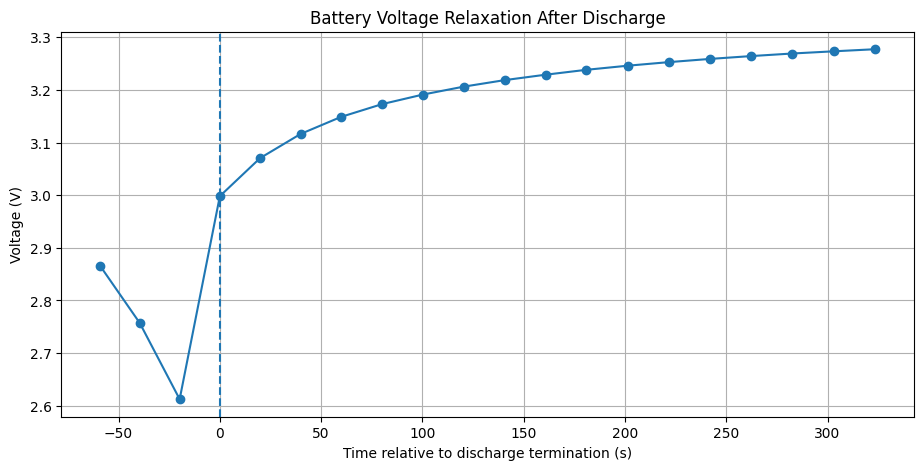

In [36]:
# Step 45: Analyse voltage relaxation after discharge termination

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Extract discharge measurements
time = np.asarray(
    discharge_data.Time, dtype=float
).flatten()

voltage = np.asarray(
    discharge_data.Voltage_measured, dtype=float
).flatten()

current = np.asarray(
    discharge_data.Current_measured, dtype=float
).flatten()

time = time - time[0]

# Find the point where discharge current returns to approximately zero
cutoff_candidates = np.where(
    (np.abs(current[:-1]) > 1.0) &
    (np.abs(current[1:]) < 0.05)
)[0]

if len(cutoff_candidates) == 0:
    print("No discharge termination point detected.")

else:
    cutoff_index = cutoff_candidates[0] + 1

    # Extract measurements from 60 seconds before cutoff
    # until the end of the record
    start_index = np.where(
        time >= time[cutoff_index] - 60
    )[0][0]

    relaxation_df = pd.DataFrame({
        "time_s": time[start_index:],
        "elapsed_after_cutoff_s":
            time[start_index:] - time[cutoff_index],
        "voltage_V": voltage[start_index:],
        "current_A": current[start_index:]
    })

    print("Discharge termination:")
    print("Time:", round(time[cutoff_index], 2), "seconds")
    print("Voltage:", round(voltage[cutoff_index], 4), "V")

    print("\nMeasurements around discharge termination:")
    print(relaxation_df.to_string(index=False))

    # Plot voltage around termination
    plt.figure(figsize=(11, 5))

    plt.plot(
        relaxation_df["elapsed_after_cutoff_s"],
        relaxation_df["voltage_V"],
        marker="o"
    )

    plt.axvline(0, linestyle="--")

    plt.xlabel("Time relative to discharge termination (s)")
    plt.ylabel("Voltage (V)")
    plt.title("Battery Voltage Relaxation After Discharge")
    plt.grid(True)
    plt.show()

EXPONENTIAL RELAXATION MODEL
--------------------------------
Estimated asymptotic voltage: 3.2757 V
Relaxation amplitude: 0.2673 V
Relaxation time constant: 85.81 seconds
RMSE: 0.00541 V
R²: 0.9950


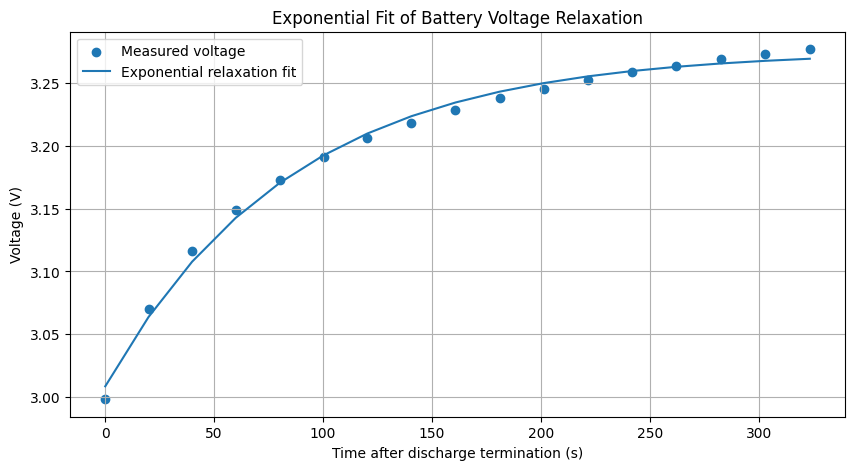

In [37]:
# Step 46: Fit an exponential voltage relaxation model

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error, r2_score

# Extract post-discharge relaxation measurements
relaxation_time = relaxation_df[
    "elapsed_after_cutoff_s"
].to_numpy()

relaxation_voltage = relaxation_df[
    "voltage_V"
].to_numpy()

# Keep only measurements after discharge termination
mask = relaxation_time >= 0

t = relaxation_time[mask]
v = relaxation_voltage[mask]

# Single-exponential relaxation function
def relaxation_model(t, V_inf, A, tau):
    return V_inf - A * np.exp(-t / tau)

# Initial parameter estimates
initial_guess = [
    3.35,  # asymptotic voltage
    0.35,  # relaxation amplitude
    100.0  # time constant in seconds
]

# Fit the model
parameters, covariance = curve_fit(
    relaxation_model,
    t,
    v,
    p0=initial_guess,
    bounds=(
        [2.5, 0.0, 1.0],
        [5.0, 2.0, 10000.0]
    ),
    maxfev=20000
)

V_inf, A, tau = parameters

# Calculate fitted voltage and performance
predicted_voltage = relaxation_model(t, *parameters)

rmse = np.sqrt(
    mean_squared_error(v, predicted_voltage)
)

r2 = r2_score(v, predicted_voltage)

# Display results
print("EXPONENTIAL RELAXATION MODEL")
print("--------------------------------")
print(f"Estimated asymptotic voltage: {V_inf:.4f} V")
print(f"Relaxation amplitude: {A:.4f} V")
print(f"Relaxation time constant: {tau:.2f} seconds")
print(f"RMSE: {rmse:.5f} V")
print(f"R²: {r2:.4f}")

# Plot measured and fitted voltage
plt.figure(figsize=(10, 5))

plt.scatter(
    t,
    v,
    label="Measured voltage"
)

plt.plot(
    t,
    predicted_voltage,
    label="Exponential relaxation fit"
)

plt.xlabel("Time after discharge termination (s)")
plt.ylabel("Voltage (V)")
plt.title("Exponential Fit of Battery Voltage Relaxation")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
# Step 47: Validate exponential relaxation across B0005 cycles

from scipy.io import loadmat
from scipy.optimize import curve_fit
import numpy as np
import pandas as pd

# Load original B0005 data
battery_file = os.path.join(
    project_folder,
    "raw_data",
    "B0005.mat"
)

mat_data = loadmat(
    battery_file,
    squeeze_me=True,
    struct_as_record=False
)

battery = mat_data["B0005"]
all_cycles = np.atleast_1d(battery.cycle)


def relaxation_model(t, V_inf, A, tau):
    return V_inf - A * np.exp(-t / tau)


results = []

discharge_records = [
    cycle for cycle in all_cycles
    if str(cycle.type).lower() == "discharge"
]

for record_index, cycle in enumerate(discharge_records):

    data = cycle.data

    time = np.asarray(
        data.Time, dtype=float
    ).flatten()

    voltage = np.asarray(
        data.Voltage_measured, dtype=float
    ).flatten()

    current = np.asarray(
        data.Current_measured, dtype=float
    ).flatten()

    time = time - time[0]

    # Detect transition from discharge to rest
    cutoff_candidates = np.where(
        (np.abs(current[:-1]) > 1.0) &
        (np.abs(current[1:]) < 0.05)
    )[0]

    if len(cutoff_candidates) == 0:
        continue

    cutoff_index = cutoff_candidates[0] + 1

    t = time[cutoff_index:] - time[cutoff_index]
    v = voltage[cutoff_index:]

    # Require at least 8 post-discharge observations
    if len(t) < 8:
        continue

    try:

        parameters, covariance = curve_fit(
            relaxation_model,
            t,
            v,
            p0=[v[-1], v[-1] - v[0], 100],
            bounds=(
                [2.5, 0.0, 1.0],
                [5.0, 2.0, 10000.0]
            ),
            maxfev=20000
        )

        V_inf, A, tau = parameters

        predicted = relaxation_model(t, *parameters)

        rmse = np.sqrt(
            np.mean((v - predicted) ** 2)
        )

        ss_res = np.sum((v - predicted) ** 2)
        ss_tot = np.sum((v - np.mean(v)) ** 2)

        r2 = (
            1 - ss_res / ss_tot
            if ss_tot > 0 else np.nan
        )

        results.append({
            "record_index": record_index,
            "V_inf": V_inf,
            "A": A,
            "tau_seconds": tau,
            "RMSE_V": rmse,
            "R2": r2,
            "observations": len(t)
        })

    except (RuntimeError, ValueError):
        continue


relaxation_results = pd.DataFrame(results)

print("RELAXATION MODEL VALIDATION")
print("--------------------------------")
print("Total discharge records:", len(discharge_records))
print("Successfully fitted records:", len(relaxation_results))

if not relaxation_results.empty:

    print("\nSummary statistics:")
    print(
        relaxation_results[
            ["V_inf", "A", "tau_seconds", "RMSE_V", "R2"]
        ].describe().round(4)
    )

    print("\nFirst 10 fitted records:")
    print(relaxation_results.head(10).round(4).to_string(index=False))

    print("\nLast 10 fitted records:")
    print(relaxation_results.tail(10).round(4).to_string(index=False))

else:
    print("No records could be fitted successfully.")

RELAXATION MODEL VALIDATION
--------------------------------
Total discharge records: 168
Successfully fitted records: 161

Summary statistics:
          V_inf         A  tau_seconds    RMSE_V        R2
count  161.0000  161.0000     161.0000  161.0000  161.0000
mean     3.4833    0.4359      82.1987    0.0095    0.9936
std      0.1115    0.0789      18.0703    0.0038    0.0033
min      3.2444    0.2673      45.9134    0.0024    0.9886
25%      3.3852    0.3696      68.3678    0.0056    0.9906
50%      3.5299    0.4732      85.8690    0.0104    0.9935
75%      3.5742    0.4982      98.4696    0.0130    0.9968
max      3.6084    0.5220     105.5191    0.0146    0.9992

First 10 fitted records:
 record_index  V_inf      A  tau_seconds  RMSE_V     R2  observations
            0 3.2757 0.2673      85.8139  0.0054 0.9950            17
            1 3.2998 0.3009      88.9236  0.0059 0.9953            17
            2 3.3265 0.2923      88.8961  0.0062 0.9945            17
            3 3.314

RELAXATION PARAMETERS VS BATTERY HEALTH

Parameter: tau_seconds
Pearson correlation:  -0.8359
Pearson p-value:      0.000000
Spearman correlation: -0.8590
Spearman p-value:     0.000000

Parameter: A
Pearson correlation:  -0.9300
Pearson p-value:      0.000000
Spearman correlation: -0.9414
Spearman p-value:     0.000000

Parameter: V_inf
Pearson correlation:  -0.9582
Pearson p-value:      0.000000
Spearman correlation: -0.9908
Spearman p-value:     0.000000


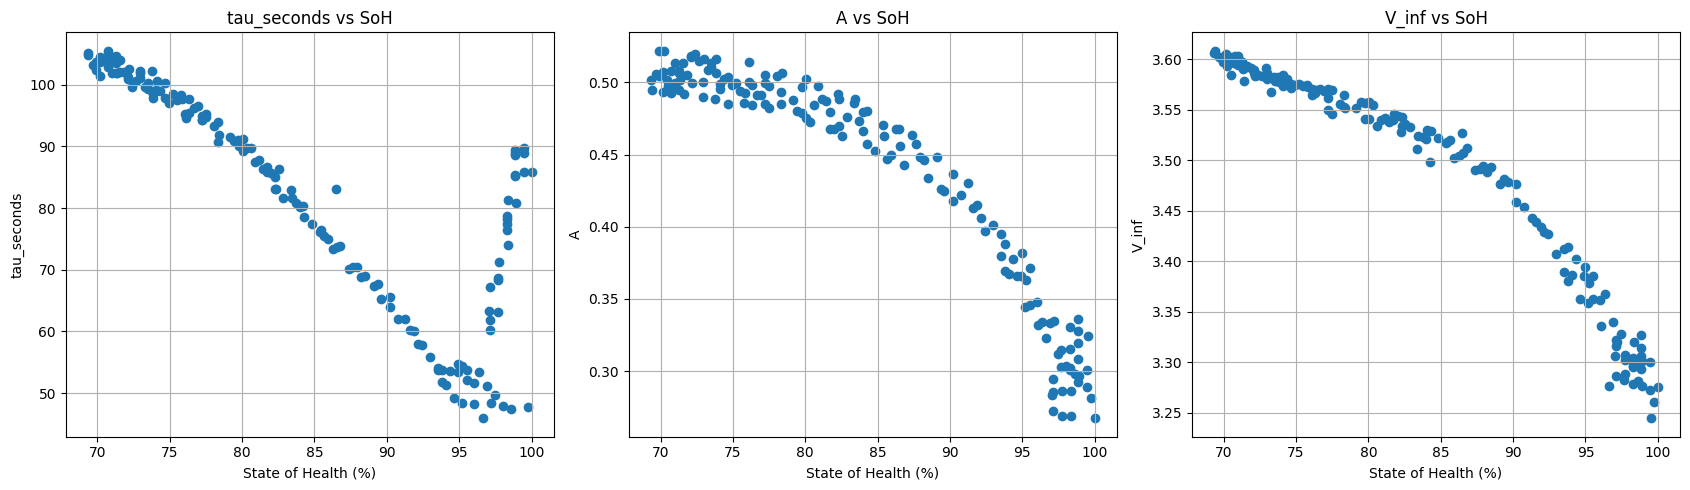

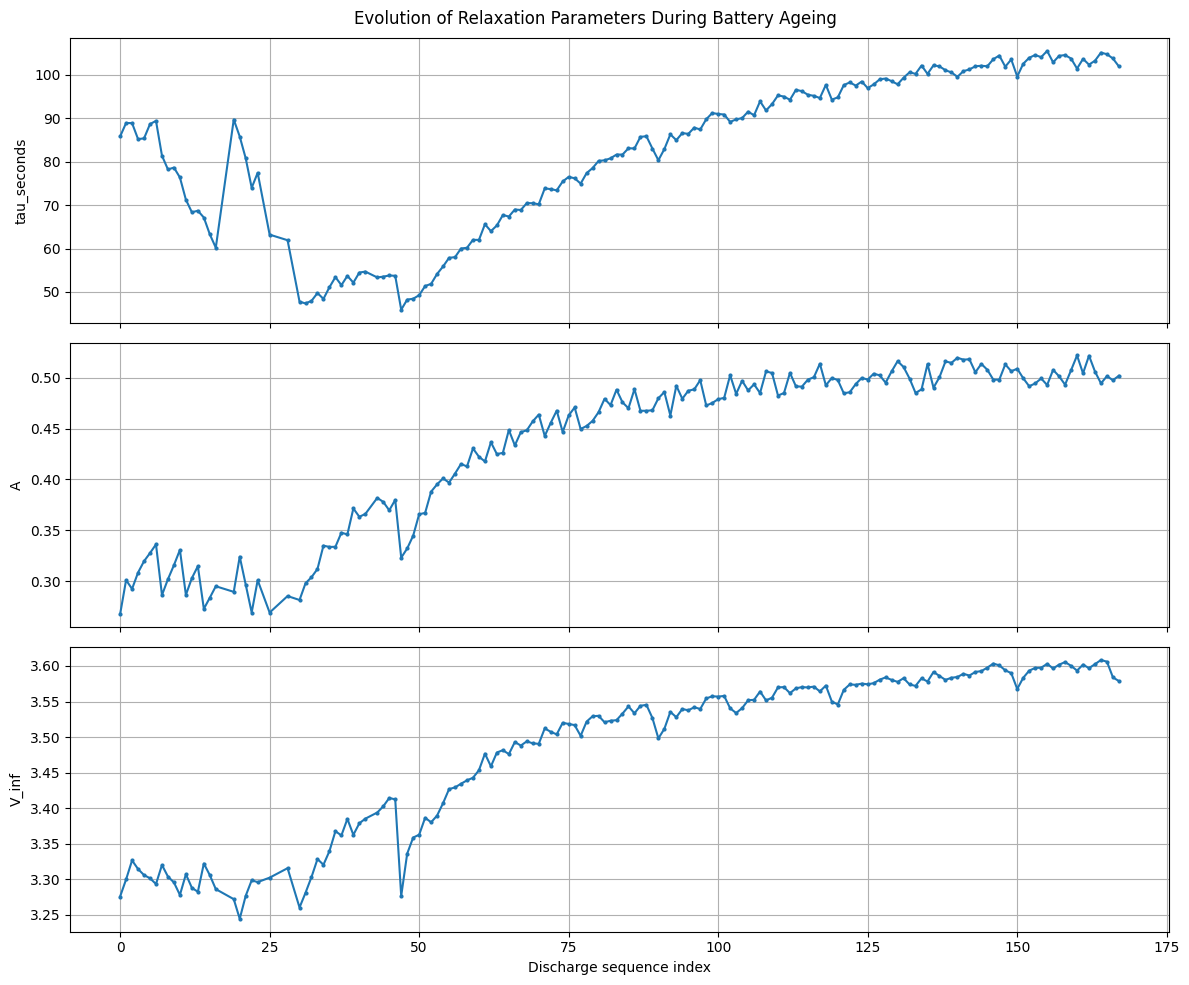

In [39]:
# Step 48: Analyse relaxation parameters against battery health

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr

# Extract capacity from each discharge record
capacity_data = []

for record_index, cycle in enumerate(discharge_records):

    capacity = float(cycle.data.Capacity)

    capacity_data.append({
        "record_index": record_index,
        "capacity_Ah": capacity
    })

capacity_df = pd.DataFrame(capacity_data)

# Calculate SoH relative to the first discharge capacity
initial_capacity = capacity_df["capacity_Ah"].iloc[0]

capacity_df["SoH_percent"] = (
    capacity_df["capacity_Ah"] / initial_capacity
) * 100

# Combine battery health and relaxation parameters
analysis_df = pd.merge(
    relaxation_results,
    capacity_df,
    on="record_index",
    how="inner"
)

# Calculate correlations
parameters_to_test = [
    "tau_seconds",
    "A",
    "V_inf"
]

print("RELAXATION PARAMETERS VS BATTERY HEALTH")
print("=" * 55)

for parameter in parameters_to_test:

    pearson_r, pearson_p = pearsonr(
        analysis_df[parameter],
        analysis_df["SoH_percent"]
    )

    spearman_r, spearman_p = spearmanr(
        analysis_df[parameter],
        analysis_df["SoH_percent"]
    )

    print(f"\nParameter: {parameter}")

    print(f"Pearson correlation:  {pearson_r:.4f}")
    print(f"Pearson p-value:      {pearson_p:.6f}")

    print(f"Spearman correlation: {spearman_r:.4f}")
    print(f"Spearman p-value:     {spearman_p:.6f}")

# Plot relaxation parameters against SoH
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, parameter in zip(axes, parameters_to_test):

    ax.scatter(
        analysis_df["SoH_percent"],
        analysis_df[parameter]
    )

    ax.set_xlabel("State of Health (%)")
    ax.set_ylabel(parameter)
    ax.set_title(f"{parameter} vs SoH")
    ax.grid(True)

plt.tight_layout()
plt.show()

# Show chronological evolution
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for ax, parameter in zip(axes, parameters_to_test):

    ax.plot(
        analysis_df["record_index"],
        analysis_df[parameter],
        marker=".",
        markersize=4
    )

    ax.set_ylabel(parameter)
    ax.grid(True)

axes[-1].set_xlabel("Discharge sequence index")

plt.suptitle("Evolution of Relaxation Parameters During Battery Ageing")
plt.tight_layout()
plt.show()

In [40]:
# Step 49: Test relaxation-health relationships
# after controlling for chronological progression

from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

parameters_to_test = [
    "tau_seconds",
    "A",
    "V_inf"
]

# Prepare chronological index
analysis_df = analysis_df.sort_values(
    "record_index"
).copy()

X = analysis_df[["record_index"]].values

# Remove chronological trend from SoH
trend_model = LinearRegression()
trend_model.fit(X, analysis_df["SoH_percent"])

analysis_df["SoH_residual"] = (
    analysis_df["SoH_percent"] -
    trend_model.predict(X)
)

print("CHRONOLOGICALLY ADJUSTED CORRELATIONS")
print("=" * 60)

for parameter in parameters_to_test:

    # Remove chronological trend from relaxation parameter
    parameter_model = LinearRegression()

    parameter_model.fit(
        X,
        analysis_df[parameter]
    )

    parameter_residual = (
        analysis_df[parameter] -
        parameter_model.predict(X)
    )

    # Correlation between detrended residuals
    pearson_r, pearson_p = pearsonr(
        parameter_residual,
        analysis_df["SoH_residual"]
    )

    spearman_r, spearman_p = spearmanr(
        parameter_residual,
        analysis_df["SoH_residual"]
    )

    print(f"\nParameter: {parameter}")

    print(
        f"Adjusted Pearson correlation: {pearson_r:.4f}"
    )

    print(
        f"Adjusted Pearson p-value: {pearson_p:.6f}"
    )

    print(
        f"Adjusted Spearman correlation: {spearman_r:.4f}"
    )

    print(
        f"Adjusted Spearman p-value: {spearman_p:.6f}"
    )

CHRONOLOGICALLY ADJUSTED CORRELATIONS

Parameter: tau_seconds
Adjusted Pearson correlation: -0.6956
Adjusted Pearson p-value: 0.000000
Adjusted Spearman correlation: -0.7240
Adjusted Spearman p-value: 0.000000

Parameter: A
Adjusted Pearson correlation: -0.4426
Adjusted Pearson p-value: 0.000000
Adjusted Spearman correlation: -0.3688
Adjusted Spearman p-value: 0.000001

Parameter: V_inf
Adjusted Pearson correlation: -0.5759
Adjusted Pearson p-value: 0.000000
Adjusted Spearman correlation: -0.4861
Adjusted Spearman p-value: 0.000000


In [41]:
# Step 50: Extract relaxation parameters from all four batteries

from scipy.io import loadmat
from scipy.optimize import curve_fit
import numpy as np
import pandas as pd
import os

def relaxation_model(t, V_inf, A, tau):
    return V_inf - A * np.exp(-t / tau)


battery_ids = ["B0005", "B0006", "B0007", "B0018"]

all_relaxation_results = []

for battery_id in battery_ids:

    print(f"\nProcessing {battery_id}...")

    battery_file = os.path.join(
        project_folder,
        "raw_data",
        f"{battery_id}.mat"
    )

    mat_data = loadmat(
        battery_file,
        squeeze_me=True,
        struct_as_record=False
    )

    battery = mat_data[battery_id]

    all_cycles = np.atleast_1d(battery.cycle)

    discharge_records = [
        cycle for cycle in all_cycles
        if str(cycle.type).lower() == "discharge"
    ]

    successful_fits = 0

    for discharge_index, cycle in enumerate(discharge_records):

        data = cycle.data

        time = np.asarray(
            data.Time, dtype=float
        ).flatten()

        voltage = np.asarray(
            data.Voltage_measured, dtype=float
        ).flatten()

        current = np.asarray(
            data.Current_measured, dtype=float
        ).flatten()

        time = time - time[0]

        # Detect discharge termination
        cutoff_candidates = np.where(
            (np.abs(current[:-1]) > 1.0) &
            (np.abs(current[1:]) < 0.05)
        )[0]

        if len(cutoff_candidates) == 0:
            continue

        cutoff_index = cutoff_candidates[0] + 1

        t = time[cutoff_index:] - time[cutoff_index]
        v = voltage[cutoff_index:]

        if len(t) < 8:
            continue

        try:

            parameters, covariance = curve_fit(
                relaxation_model,
                t,
                v,
                p0=[v[-1], v[-1] - v[0], 100],
                bounds=(
                    [2.5, 0.0, 1.0],
                    [5.0, 2.0, 10000.0]
                ),
                maxfev=20000
            )

            V_inf, A, tau = parameters

            predicted = relaxation_model(t, *parameters)

            rmse = np.sqrt(
                np.mean((v - predicted) ** 2)
            )

            ss_res = np.sum((v - predicted) ** 2)
            ss_tot = np.sum((v - np.mean(v)) ** 2)

            r2 = (
                1 - ss_res / ss_tot
                if ss_tot > 0 else np.nan
            )

            all_relaxation_results.append({
                "battery_id": battery_id,
                "discharge_index": discharge_index,
                "V_inf": V_inf,
                "A": A,
                "tau_seconds": tau,
                "RMSE_V": rmse,
                "R2": r2,
                "observations": len(t)
            })

            successful_fits += 1

        except (RuntimeError, ValueError):
            continue

    print(
        f"Successful fits: {successful_fits} "
        f"/ {len(discharge_records)}"
    )


all_relaxation_df = pd.DataFrame(all_relaxation_results)

print("\nOVERALL RESULTS")
print("=" * 45)

print(
    all_relaxation_df.groupby("battery_id").agg(
        successful_fits=("tau_seconds", "count"),
        mean_tau=("tau_seconds", "mean"),
        mean_amplitude=("A", "mean"),
        mean_R2=("R2", "mean"),
        mean_RMSE=("RMSE_V", "mean")
    ).round(4)
)

# Save the results
output_path = os.path.join(
    results_folder,
    "relaxation_parameters_all_batteries.csv"
)

all_relaxation_df.to_csv(output_path, index=False)

print("\nResults saved to:")
print(output_path)


Processing B0005...
Successful fits: 161 / 168

Processing B0006...
Successful fits: 131 / 168

Processing B0007...
Successful fits: 109 / 168

Processing B0018...
Successful fits: 132 / 132

OVERALL RESULTS
            successful_fits  mean_tau  mean_amplitude  mean_R2  mean_RMSE
battery_id                                                               
B0005                   161   82.1987          0.4359   0.9936     0.0095
B0006                   131   83.2308          0.5523   0.9912     0.0132
B0007                   109   54.4388          0.5382   0.9976     0.0072
B0018                   132   72.0951          0.5031   0.9953     0.0096

Results saved to:
/content/drive/MyDrive/Battery_Digital_Twin/results/relaxation_parameters_all_batteries.csv


RELAXATION PARAMETERS VS SOH

B0005 | Observations: 161
-------------------------------------------------------
tau_seconds: Pearson=-0.836, Spearman=-0.859, Detrended Pearson=-0.696
A: Pearson=-0.930, Spearman=-0.941, Detrended Pearson=-0.443
V_inf: Pearson=-0.958, Spearman=-0.991, Detrended Pearson=-0.576

B0006 | Observations: 131
-------------------------------------------------------
tau_seconds: Pearson=-0.407, Spearman=0.018, Detrended Pearson=-0.867
A: Pearson=-0.832, Spearman=-0.714, Detrended Pearson=-0.749
V_inf: Pearson=-0.981, Spearman=-0.997, Detrended Pearson=-0.835

B0007 | Observations: 109
-------------------------------------------------------
tau_seconds: Pearson=-0.527, Spearman=-0.789, Detrended Pearson=0.381
A: Pearson=-0.968, Spearman=-0.971, Detrended Pearson=-0.839
V_inf: Pearson=-0.941, Spearman=-0.959, Detrended Pearson=-0.737

B0018 | Observations: 132
-------------------------------------------------------
tau_seconds: Pearson=-0.784, Spearman=-0.611, Detr

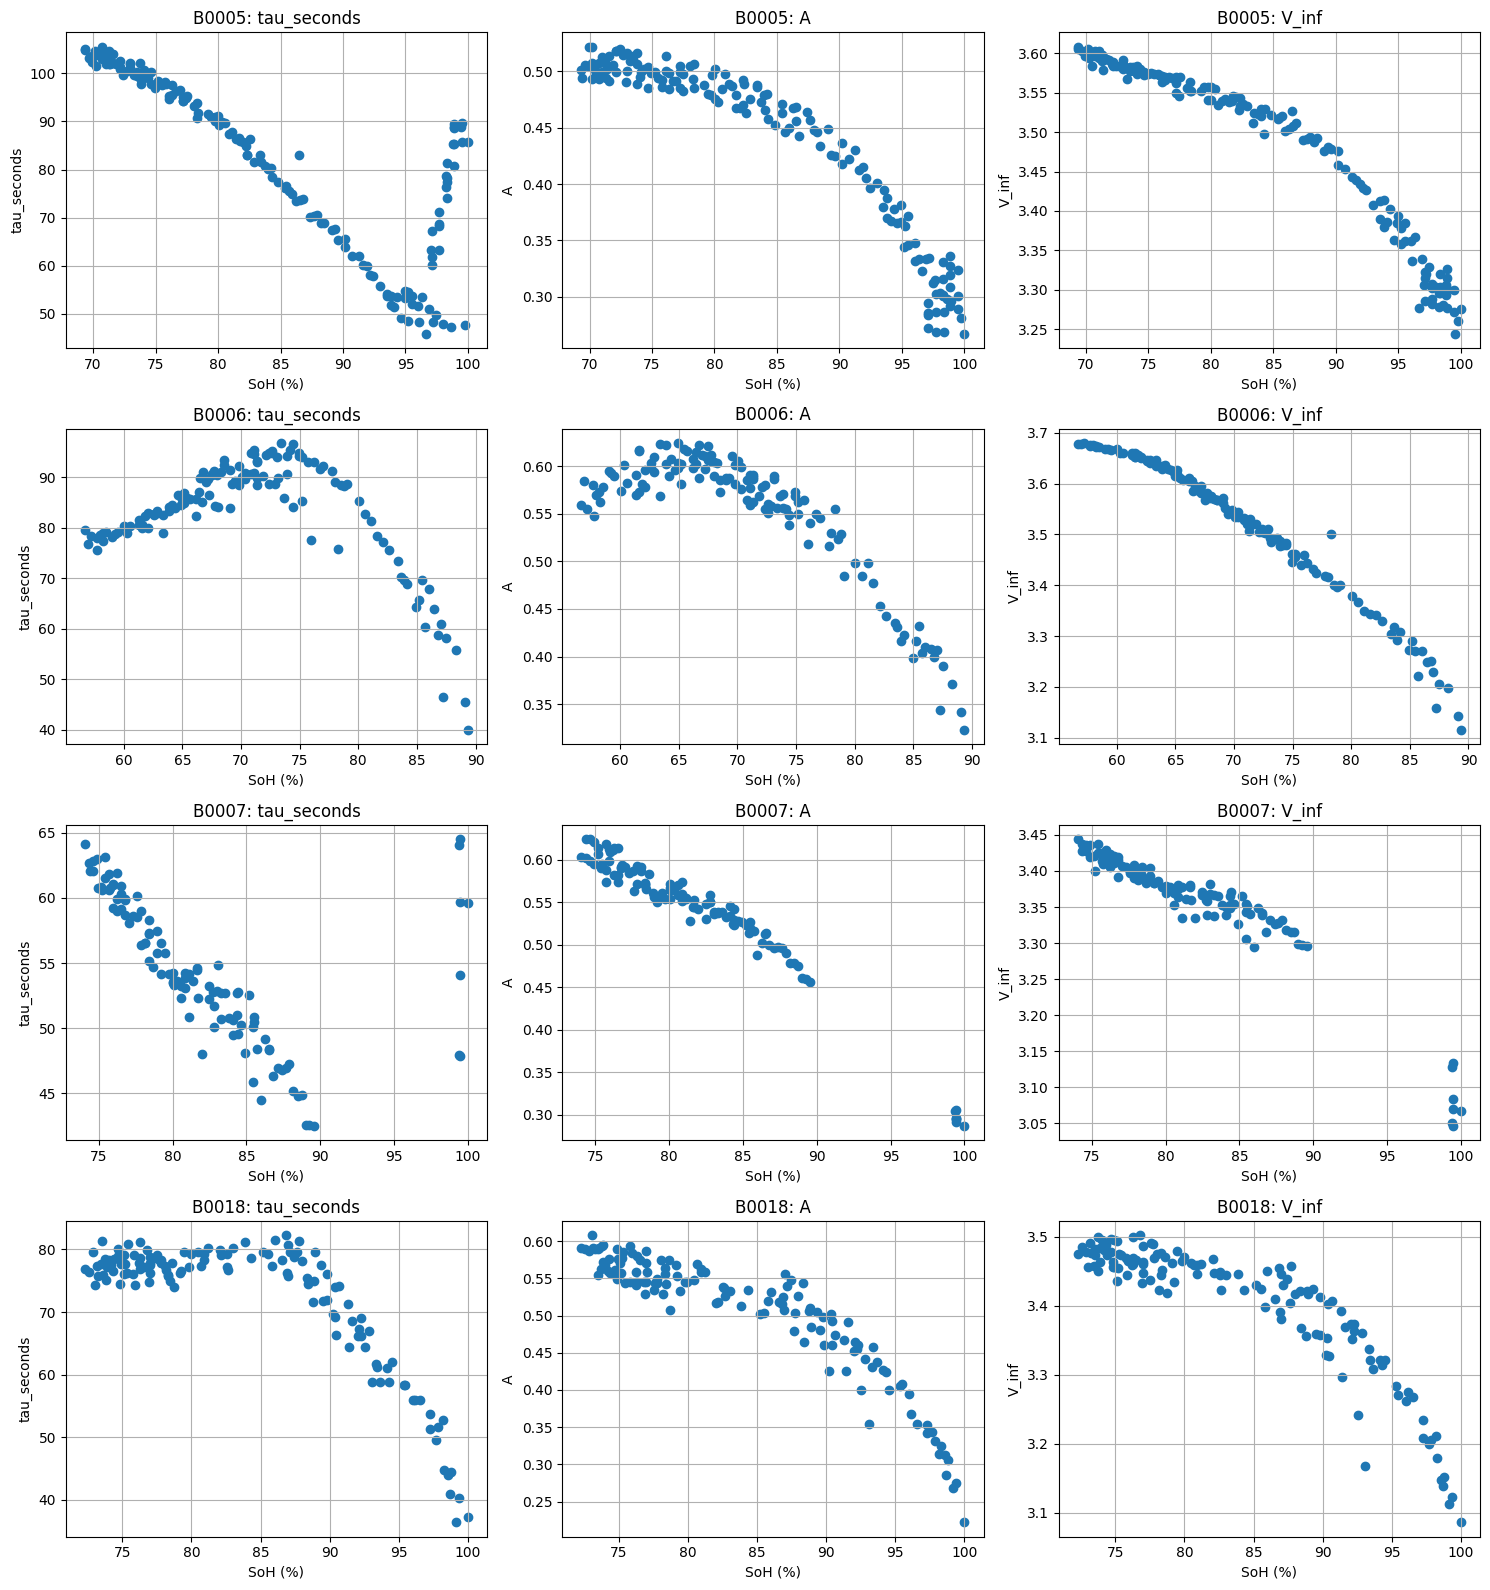


Correlation results saved to:
/content/drive/MyDrive/Battery_Digital_Twin/results/relaxation_soh_correlations_all_batteries.csv


In [42]:
# Step 51: Compare relaxation parameters with SoH
# across all four batteries

import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

battery_ids = ["B0005", "B0006", "B0007", "B0018"]

health_records = []

for battery_id in battery_ids:

    battery_file = os.path.join(
        project_folder,
        "raw_data",
        f"{battery_id}.mat"
    )

    mat_data = loadmat(
        battery_file,
        squeeze_me=True,
        struct_as_record=False
    )

    battery = mat_data[battery_id]

    cycles = np.atleast_1d(battery.cycle)

    discharge_records = [
        cycle for cycle in cycles
        if str(cycle.type).lower() == "discharge"
    ]

    capacities = [
        float(cycle.data.Capacity)
        for cycle in discharge_records
    ]

    initial_capacity = capacities[0]

    for discharge_index, capacity in enumerate(capacities):

        health_records.append({
            "battery_id": battery_id,
            "discharge_index": discharge_index,
            "capacity_Ah": capacity,
            "SoH_percent": (
                capacity / initial_capacity
            ) * 100
        })


health_df = pd.DataFrame(health_records)

# Merge health and relaxation results
validation_df = pd.merge(
    all_relaxation_df,
    health_df,
    on=["battery_id", "discharge_index"],
    how="inner"
)

parameters_to_test = [
    "tau_seconds",
    "A",
    "V_inf"
]

print("RELAXATION PARAMETERS VS SOH")
print("=" * 70)

summary_results = []

for battery_id in battery_ids:

    battery_data = validation_df[
        validation_df["battery_id"] == battery_id
    ].copy()

    print(f"\n{battery_id} | Observations: {len(battery_data)}")
    print("-" * 55)

    for parameter in parameters_to_test:

        pearson_r, pearson_p = pearsonr(
            battery_data[parameter],
            battery_data["SoH_percent"]
        )

        spearman_r, spearman_p = spearmanr(
            battery_data[parameter],
            battery_data["SoH_percent"]
        )

        # Remove linear chronological trends
        X = battery_data[["discharge_index"]].values

        model_x = LinearRegression()
        model_x.fit(X, battery_data[parameter])

        residual_x = (
            battery_data[parameter] -
            model_x.predict(X)
        )

        model_y = LinearRegression()
        model_y.fit(X, battery_data["SoH_percent"])

        residual_y = (
            battery_data["SoH_percent"] -
            model_y.predict(X)
        )

        adjusted_r, adjusted_p = pearsonr(
            residual_x,
            residual_y
        )

        print(
            f"{parameter}: "
            f"Pearson={pearson_r:.3f}, "
            f"Spearman={spearman_r:.3f}, "
            f"Detrended Pearson={adjusted_r:.3f}"
        )

        summary_results.append({
            "battery_id": battery_id,
            "parameter": parameter,
            "observations": len(battery_data),
            "pearson_r": pearson_r,
            "spearman_r": spearman_r,
            "detrended_pearson_r": adjusted_r
        })


summary_df = pd.DataFrame(summary_results)

# Visual comparison across batteries
fig, axes = plt.subplots(
    4, 3,
    figsize=(15, 16)
)

for row, battery_id in enumerate(battery_ids):

    battery_data = validation_df[
        validation_df["battery_id"] == battery_id
    ]

    for col, parameter in enumerate(parameters_to_test):

        axes[row, col].scatter(
            battery_data["SoH_percent"],
            battery_data[parameter]
        )

        axes[row, col].set_title(
            f"{battery_id}: {parameter}"
        )

        axes[row, col].set_xlabel("SoH (%)")
        axes[row, col].set_ylabel(parameter)
        axes[row, col].grid(True)

plt.tight_layout()
plt.show()

# Export results
summary_path = os.path.join(
    results_folder,
    "relaxation_soh_correlations_all_batteries.csv"
)

summary_df.to_csv(summary_path, index=False)

print("\nCorrelation results saved to:")
print(summary_path)

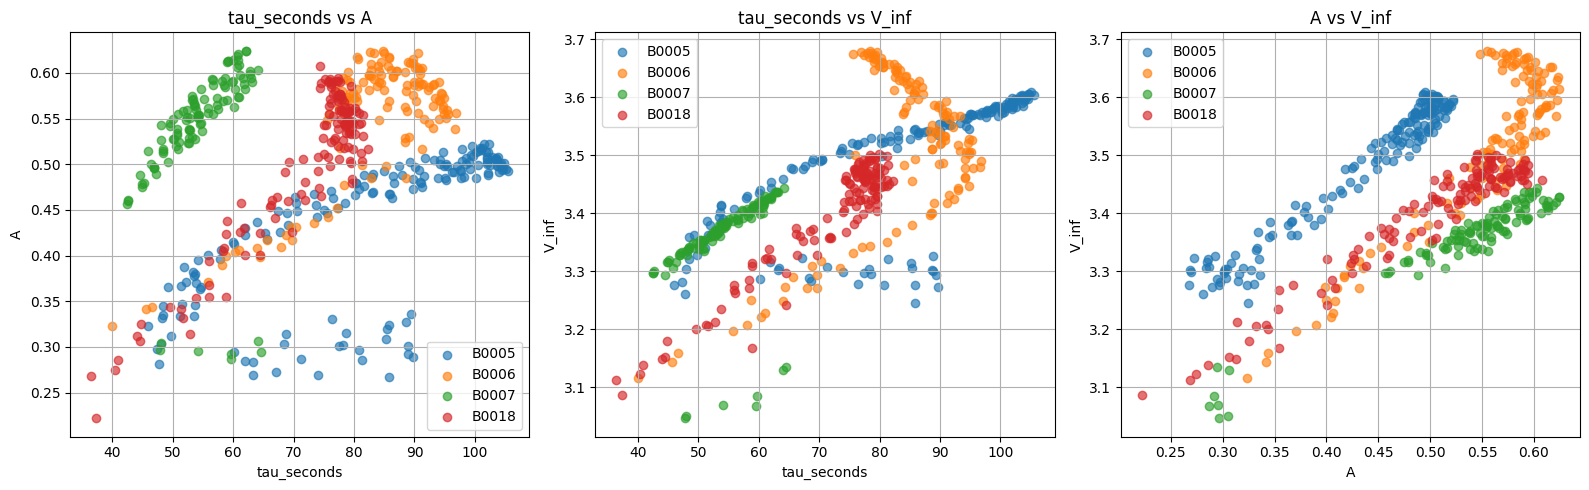

RELAXATION PARAMETER INTERDEPENDENCE

B0005
             tau_seconds      A  V_inf
tau_seconds        1.000  0.704  0.739
A                  0.704  1.000  0.977
V_inf              0.739  0.977  1.000

B0006
             tau_seconds      A  V_inf
tau_seconds        1.000  0.766  0.529
A                  0.766  1.000  0.901
V_inf              0.529  0.901  1.000

B0007
             tau_seconds      A  V_inf
tau_seconds        1.000  0.354  0.341
A                  0.354  1.000  0.968
V_inf              0.341  0.968  1.000

B0018
             tau_seconds      A  V_inf
tau_seconds        1.000  0.919  0.953
A                  0.919  1.000  0.964
V_inf              0.953  0.964  1.000


In [43]:
# Step 52: Investigate relationships between fitted parameters

import matplotlib.pyplot as plt
import pandas as pd

parameters = [
    "tau_seconds",
    "A",
    "V_inf"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

parameter_pairs = [
    ("tau_seconds", "A"),
    ("tau_seconds", "V_inf"),
    ("A", "V_inf")
]

for ax, (x_parameter, y_parameter) in zip(
    axes, parameter_pairs
):

    for battery_id in battery_ids:

        battery_data = all_relaxation_df[
            all_relaxation_df["battery_id"] == battery_id
        ]

        ax.scatter(
            battery_data[x_parameter],
            battery_data[y_parameter],
            label=battery_id,
            alpha=0.65
        )

    ax.set_xlabel(x_parameter)
    ax.set_ylabel(y_parameter)
    ax.set_title(f"{x_parameter} vs {y_parameter}")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


# Calculate correlations separately for each battery

print("RELAXATION PARAMETER INTERDEPENDENCE")
print("=" * 65)

for battery_id in battery_ids:

    battery_data = all_relaxation_df[
        all_relaxation_df["battery_id"] == battery_id
    ]

    print(f"\n{battery_id}")

    print(
        battery_data[parameters]
        .corr(method="pearson")
        .round(3)
    )

In [44]:
# Step 53: Inspect indexing before merging physical features

print("COMBINED DATASET")
print("=" * 50)

print("Shape:", combined_df.shape)

print("\nFirst 10 rows:")
print(
    combined_df[
        ["battery_id", "record_index", "capacity_Ah", "SoH_percent"]
    ].head(10).to_string(index=False)
)

print("\nRelaxation dataset")
print("=" * 50)

print(
    all_relaxation_df[
        ["battery_id", "discharge_index", "tau_seconds", "A", "V_inf"]
    ].head(10).to_string(index=False)
)

print("\nNumber of observations per battery")

print("\nCombined dataset:")
print(combined_df.groupby("battery_id").size())

print("\nRelaxation dataset:")
print(all_relaxation_df.groupby("battery_id").size())

COMBINED DATASET
Shape: (636, 20)

First 10 rows:
battery_id  record_index  capacity_Ah  SoH_percent
     B0005             1     1.856487   100.000000
     B0005             3     1.846327    99.452721
     B0005             5     1.835349    98.861386
     B0005             7     1.835263    98.856718
     B0005             9     1.834646    98.823482
     B0005            11     1.835662    98.878217
     B0005            13     1.835146    98.850449
     B0005            15     1.825757    98.344690
     B0005            17     1.824774    98.291743
     B0005            19     1.824613    98.283094

Relaxation dataset
battery_id  discharge_index  tau_seconds        A    V_inf
     B0005                0    85.813939 0.267315 3.275744
     B0005                1    88.923603 0.300949 3.299791
     B0005                2    88.896064 0.292268 3.326541
     B0005                3    85.219167 0.308335 3.314459
     B0005                4    85.375904 0.319537 3.305879
     B0005     

In [45]:
# Step 54: Align relaxation parameters with discharge observations

import pandas as pd
import numpy as np

# Copy and sort the original dataset
model_dataset_C = combined_df.copy()

model_dataset_C = model_dataset_C.sort_values(
    ["battery_id", "record_index"]
).reset_index(drop=True)

# Create sequential discharge index within each battery
model_dataset_C["discharge_index"] = (
    model_dataset_C.groupby("battery_id").cumcount()
)

# Merge relaxation parameters
model_dataset_C = pd.merge(
    model_dataset_C,
    all_relaxation_df[
        [
            "battery_id",
            "discharge_index",
            "tau_seconds",
            "A",
            "V_inf",
            "RMSE_V",
            "R2"
        ]
    ],
    on=["battery_id", "discharge_index"],
    how="left",
    validate="one_to_one"
)

# Check alignment and coverage
print("DATASET ALIGNMENT VALIDATION")
print("=" * 55)

print("Combined dataset shape:", combined_df.shape)
print("Merged dataset shape:", model_dataset_C.shape)

print("\nRelaxation feature availability:")

print(
    model_dataset_C.groupby("battery_id").agg(
        total_observations=("discharge_index", "count"),
        available_tau=("tau_seconds", "count"),
        available_A=("A", "count"),
        available_V_inf=("V_inf", "count")
    )
)

print("\nMissing relaxation values:")
print(
    model_dataset_C[
        ["tau_seconds", "A", "V_inf"]
    ].isna().sum()
)

print("\nFirst 10 aligned observations:")

print(
    model_dataset_C[
        [
            "battery_id",
            "record_index",
            "discharge_index",
            "SoH_percent",
            "tau_seconds",
            "A",
            "V_inf"
        ]
    ].head(10).to_string(index=False)
)

# Save merged dataset
output_path = os.path.join(
    results_folder,
    "combined_dataset_with_relaxation.csv"
)

model_dataset_C.to_csv(output_path, index=False)

print("\nMerged dataset saved to:")
print(output_path)

DATASET ALIGNMENT VALIDATION
Combined dataset shape: (636, 20)
Merged dataset shape: (636, 26)

Relaxation feature availability:
            total_observations  available_tau  available_A  available_V_inf
battery_id                                                                 
B0005                      168            161          161              161
B0006                      168            131          131              131
B0007                      168            109          109              109
B0018                      132            132          132              132

Missing relaxation values:
tau_seconds    103
A              103
V_inf          103
dtype: int64

First 10 aligned observations:
battery_id  record_index  discharge_index  SoH_percent  tau_seconds        A    V_inf
     B0005             1                0   100.000000    85.813939 0.267315 3.275744
     B0005             3                1    99.452721    88.923603 0.300949 3.299791
     B0005             5   

In [46]:
# Step 55: LOBO validation of relaxation-enhanced SoH models

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd

# Existing electrical and thermal features
base_features = [
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "current_mean",
    "temperature_mean",
    "temperature_max",
    "temperature_rise"
]

# Define candidate models
model_features = {
    "Baseline": base_features,

    "Baseline + tau": base_features + [
        "tau_seconds"
    ],

    "Baseline + A": base_features + [
        "A"
    ],

    "Baseline + V_inf": base_features + [
        "V_inf"
    ],

    "Baseline + all relaxation": base_features + [
        "tau_seconds",
        "A",
        "V_inf"
    ]
}

# Use identical observations for every model
required_columns = (
    base_features +
    ["tau_seconds", "A", "V_inf", "SoH_percent"]
)

evaluation_df = model_dataset_C.dropna(
    subset=required_columns
).copy()

print("FAIR EVALUATION DATASET")
print("=" * 50)

print("Total observations:", len(evaluation_df))

print("\nObservations per battery:")
print(evaluation_df.groupby("battery_id").size())

results = []

battery_ids = sorted(evaluation_df["battery_id"].unique())

for held_out_battery in battery_ids:

    train_df = evaluation_df[
        evaluation_df["battery_id"] != held_out_battery
    ]

    test_df = evaluation_df[
        evaluation_df["battery_id"] == held_out_battery
    ]

    print(f"\nTesting on {held_out_battery}")
    print(
        f"Training observations: {len(train_df)} | "
        f"Test observations: {len(test_df)}"
    )

    y_train = train_df["SoH_percent"]
    y_test = test_df["SoH_percent"]

    for model_name, features in model_features.items():

        X_train = train_df[features]
        X_test = test_df[features]

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=1.0))
        ])

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        mae = mean_absolute_error(
            y_test,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(y_test, predictions)
        )

        r2 = r2_score(
            y_test,
            predictions
        )

        results.append({
            "held_out_battery": held_out_battery,
            "model": model_name,
            "observations": len(test_df),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })


# Organise results
lobo_relaxation_results = pd.DataFrame(results)

print("\nLOBO MODEL COMPARISON")
print("=" * 70)

print(
    lobo_relaxation_results.round(4).to_string(index=False)
)

# Calculate observation-weighted overall metrics
overall_results = []

for model_name in model_features:

    model_data = lobo_relaxation_results[
        lobo_relaxation_results["model"] == model_name
    ]

    weighted_mae = np.average(
        model_data["MAE"],
        weights=model_data["observations"]
    )

    weighted_rmse = np.sqrt(
        np.average(
            model_data["RMSE"] ** 2,
            weights=model_data["observations"]
        )
    )

    overall_results.append({
        "model": model_name,
        "weighted_MAE": weighted_mae,
        "weighted_RMSE": weighted_rmse
    })

overall_df = pd.DataFrame(overall_results)

print("\nOVERALL WEIGHTED PERFORMANCE")
print("=" * 55)

print(overall_df.round(4).to_string(index=False))

# Calculate improvement relative to baseline
baseline_mae = overall_df.loc[
    overall_df["model"] == "Baseline",
    "weighted_MAE"
].iloc[0]

overall_df["MAE_improvement_percent"] = (
    (baseline_mae - overall_df["weighted_MAE"])
    / baseline_mae
) * 100

print("\nIMPROVEMENT RELATIVE TO BASELINE")
print("=" * 55)

print(
    overall_df[
        ["model", "MAE_improvement_percent"]
    ].round(2).to_string(index=False)
)

# Save results
output_path = os.path.join(
    results_folder,
    "lobo_relaxation_model_comparison.csv"
)

lobo_relaxation_results.to_csv(
    output_path,
    index=False
)

overall_df.to_csv(
    os.path.join(
        results_folder,
        "lobo_relaxation_overall_results.csv"
    ),
    index=False
)

print("\nResults saved to:")
print(output_path)

FAIR EVALUATION DATASET
Total observations: 533

Observations per battery:
battery_id
B0005    161
B0006    131
B0007    109
B0018    132
dtype: int64

Testing on B0005
Training observations: 372 | Test observations: 161

Testing on B0006
Training observations: 402 | Test observations: 131

Testing on B0007
Training observations: 424 | Test observations: 109

Testing on B0018
Training observations: 401 | Test observations: 132

LOBO MODEL COMPARISON
held_out_battery                     model  observations    MAE   RMSE     R2
           B0005                  Baseline           161 1.6197 2.1150 0.9561
           B0005            Baseline + tau           161 3.1494 3.7153 0.8647
           B0005              Baseline + A           161 1.2150 1.7620 0.9696
           B0005          Baseline + V_inf           161 1.5367 1.9927 0.9611
           B0005 Baseline + all relaxation           161 3.6677 4.5602 0.7961
           B0006                  Baseline           131 3.7047 4.2405 0.7495


In [47]:
# Step 56: Investigate relaxation parameter distributions
# across the four batteries

import pandas as pd
import numpy as np

relaxation_features = [
    "tau_seconds",
    "A",
    "V_inf"
]

print("RELAXATION PARAMETER DISTRIBUTIONS")
print("=" * 75)

distribution_summary = (
    model_dataset_C
    .groupby("battery_id")[relaxation_features]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

print(distribution_summary.round(4).to_string())

# Calculate the relationship between each parameter and SoH
print("\n\nPARAMETER-SOH CORRELATIONS BY BATTERY")
print("=" * 75)

for battery_id in sorted(model_dataset_C["battery_id"].unique()):

    battery_df = model_dataset_C[
        model_dataset_C["battery_id"] == battery_id
    ].dropna(
        subset=relaxation_features + ["SoH_percent"]
    )

    print(f"\n{battery_id} | Observations: {len(battery_df)}")

    for feature in relaxation_features:

        pearson_corr = battery_df[feature].corr(
            battery_df["SoH_percent"],
            method="pearson"
        )

        spearman_corr = battery_df[feature].corr(
            battery_df["SoH_percent"],
            method="spearman"
        )

        print(
            f"{feature:15s} | "
            f"Pearson: {pearson_corr: .3f} | "
            f"Spearman: {spearman_corr: .3f}"
        )

# Compare battery-specific mean values
print("\n\nBATTERY-SPECIFIC MEAN VALUES")
print("=" * 75)

print(
    model_dataset_C
    .groupby("battery_id")[relaxation_features]
    .mean()
    .round(4)
)

RELAXATION PARAMETER DISTRIBUTIONS
           tau_seconds                                                   A                                         V_inf                                        
                 count     mean      std      min   median       max count    mean     std     min  median     max count    mean     std     min  median     max
battery_id                                                                                                                                                      
B0005              161  82.1987  18.0703  45.9134  85.8690  105.5191   161  0.4359  0.0789  0.2673  0.4732  0.5220   161  3.4833  0.1115  3.2444  3.5299  3.6084
B0006              131  83.2308  10.6304  39.9947  85.0260   96.8092   131  0.5523  0.0695  0.3231  0.5768  0.6243   131  3.5152  0.1380  3.1154  3.5403  3.6801
B0007              109  54.4388   5.5397  42.4817  54.1563   64.5093   109  0.5382  0.0744  0.2869  0.5537  0.6241   109  3.3567  0.0809  3.0463  3.3742  3.4441

In [48]:
# Step 57: Calculate apparent RC parameters from voltage relaxation

import numpy as np
import pandas as pd
import os

# Work on a copy
rc_dataset = model_dataset_C.copy()

# Use the mean discharge current as an approximation
# of the current immediately before interruption
rc_dataset["discharge_current_A"] = (
    rc_dataset["current_mean"].abs()
)

# Apparent polarisation resistance (Ohms)
rc_dataset["R_app_ohm"] = (
    rc_dataset["A"] /
    rc_dataset["discharge_current_A"]
)

# Apparent capacitance (Farads)
rc_dataset["C_app_F"] = (
    rc_dataset["tau_seconds"] /
    rc_dataset["R_app_ohm"]
)

# Remove invalid or non-positive estimates
valid_mask = (
    np.isfinite(rc_dataset["R_app_ohm"]) &
    np.isfinite(rc_dataset["C_app_F"]) &
    (rc_dataset["R_app_ohm"] > 0) &
    (rc_dataset["C_app_F"] > 0) &
    (rc_dataset["discharge_current_A"] > 0)
)

rc_dataset.loc[
    ~valid_mask,
    ["R_app_ohm", "C_app_F"]
] = np.nan

# Summary statistics by battery
print("APPARENT RC PARAMETER DISTRIBUTIONS")
print("=" * 65)

summary = (
    rc_dataset
    .groupby("battery_id")
    [["R_app_ohm", "C_app_F"]]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

print(summary.round(4).to_string())

# Correlations with SoH within each battery
print("\n\nAPPARENT RC PARAMETERS VS SOH")
print("=" * 65)

for battery_id in sorted(rc_dataset["battery_id"].unique()):

    battery_df = rc_dataset[
        rc_dataset["battery_id"] == battery_id
    ].dropna(
        subset=["R_app_ohm", "C_app_F", "SoH_percent"]
    )

    print(f"\n{battery_id} | Observations: {len(battery_df)}")

    for feature in ["R_app_ohm", "C_app_F"]:

        pearson = battery_df[feature].corr(
            battery_df["SoH_percent"],
            method="pearson"
        )

        spearman = battery_df[feature].corr(
            battery_df["SoH_percent"],
            method="spearman"
        )

        print(
            f"{feature:12s} | "
            f"Pearson: {pearson: .3f} | "
            f"Spearman: {spearman: .3f}"
        )

# Save results
output_path = os.path.join(
    results_folder,
    "apparent_RC_parameters.csv"
)

rc_dataset.to_csv(output_path, index=False)

print("\nResults saved to:")
print(output_path)

APPARENT RC PARAMETER DISTRIBUTIONS
           R_app_ohm                                         C_app_F                                                 
               count    mean     std     min  median     max   count      mean      std       min    median       max
battery_id                                                                                                           
B0005            161  0.2440  0.0526  0.1413  0.2623  0.3115     161  342.0936  66.7726  256.7330  331.4084  583.8425
B0006            131  0.3226  0.0540  0.1653  0.3396  0.3832     131  262.0678  34.2448  200.6020  262.3861  332.5207
B0007            109  0.2858  0.0413  0.1535  0.2933  0.3388     109  195.3306  44.8815  168.9254  184.6008  408.6180
B0018            132  0.2756  0.0516  0.1136  0.2941  0.3398     132  264.6034  21.7409  218.7902  263.7451  328.2730


APPARENT RC PARAMETERS VS SOH

B0005 | Observations: 161
R_app_ohm    | Pearson: -0.970 | Spearman: -0.976
C_app_F      | Pearson:  0.25

In [49]:
# Step 58: Recalculate apparent resistance using
# the current immediately before discharge termination

import numpy as np
import pandas as pd
from scipy.io import loadmat
import os

battery_ids = ["B0005", "B0006", "B0007", "B0018"]

cutoff_current_results = []

for battery_id in battery_ids:

    battery_file = os.path.join(
        project_folder,
        "raw_data",
        f"{battery_id}.mat"
    )

    mat_data = loadmat(
        battery_file,
        squeeze_me=True,
        struct_as_record=False
    )

    battery = mat_data[battery_id]
    cycles = np.atleast_1d(battery.cycle)

    discharge_records = [
        cycle for cycle in cycles
        if str(cycle.type).lower() == "discharge"
    ]

    for discharge_index, cycle in enumerate(discharge_records):

        current = np.asarray(
            cycle.data.Current_measured,
            dtype=float
        ).flatten()

        # Find the transition from discharge current
        # to approximately zero current
        cutoff_candidates = np.where(
            (np.abs(current[:-1]) > 1.0) &
            (np.abs(current[1:]) < 0.05)
        )[0]

        if len(cutoff_candidates) == 0:
            continue

        cutoff_index = cutoff_candidates[0] + 1

        # Current immediately before termination
        current_before_cutoff = abs(
            current[cutoff_index - 1]
        )

        cutoff_current_results.append({
            "battery_id": battery_id,
            "discharge_index": discharge_index,
            "current_before_cutoff_A": current_before_cutoff
        })


cutoff_current_df = pd.DataFrame(cutoff_current_results)

# Merge with relaxation estimates
improved_rc_df = pd.merge(
    all_relaxation_df,
    cutoff_current_df,
    on=["battery_id", "discharge_index"],
    how="inner"
)

# Calculate revised apparent resistance
improved_rc_df["R_app_cutoff_ohm"] = (
    improved_rc_df["A"] /
    improved_rc_df["current_before_cutoff_A"]
)

# Merge with SoH
improved_rc_df = pd.merge(
    improved_rc_df,
    health_df[
        ["battery_id", "discharge_index", "SoH_percent"]
    ],
    on=["battery_id", "discharge_index"],
    how="left"
)

# Compare old and revised resistance
old_resistance = rc_dataset[
    ["battery_id", "discharge_index", "R_app_ohm"]
]

improved_rc_df = pd.merge(
    improved_rc_df,
    old_resistance,
    on=["battery_id", "discharge_index"],
    how="left"
)

print("RESISTANCE ESTIMATION COMPARISON")
print("=" * 65)

for battery_id in battery_ids:

    battery_df = improved_rc_df[
        improved_rc_df["battery_id"] == battery_id
    ]

    print(f"\n{battery_id}")

    print(
        "Mean current before cutoff:",
        round(
            battery_df["current_before_cutoff_A"].mean(),
            4
        ),
        "A"
    )

    print(
        "Mean revised apparent resistance:",
        round(
            battery_df["R_app_cutoff_ohm"].mean(),
            4
        ),
        "Ohm"
    )

    print(
        "Correlation with SoH:",
        round(
            battery_df["R_app_cutoff_ohm"].corr(
                battery_df["SoH_percent"]
            ),
            4
        )
    )

    print(
        "Old mean resistance:",
        round(
            battery_df["R_app_ohm"].mean(),
            4
        ),
        "Ohm"
    )

# Save revised estimates
output_path = os.path.join(
    results_folder,
    "revised_apparent_resistance.csv"
)

improved_rc_df.to_csv(output_path, index=False)

print("\nResults saved to:")
print(output_path)

RESISTANCE ESTIMATION COMPARISON

B0005
Mean current before cutoff: 2.0125 A
Mean revised apparent resistance: 0.2166 Ohm
Correlation with SoH: -0.9299
Old mean resistance: 0.244 Ohm

B0006
Mean current before cutoff: 2.0104 A
Mean revised apparent resistance: 0.2747 Ohm
Correlation with SoH: -0.8322
Old mean resistance: 0.3226 Ohm

B0007
Mean current before cutoff: 1.9873 A
Mean revised apparent resistance: 0.2708 Ohm
Correlation with SoH: -0.968
Old mean resistance: 0.2858 Ohm

B0018
Mean current before cutoff: 2.0093 A
Mean revised apparent resistance: 0.2504 Ohm
Correlation with SoH: -0.9035
Old mean resistance: 0.2756 Ohm

Results saved to:
/content/drive/MyDrive/Battery_Digital_Twin/results/revised_apparent_resistance.csv


In [50]:
import os
import pandas as pd

# Load the revised resistance results
revised_path = os.path.join(
    results_folder,
    "revised_apparent_resistance.csv"
)

revised_df = pd.read_csv(revised_path)

print("=" * 65)
print(" REVISED RESISTANCE DATA VALIDATION")
print("=" * 65)

# 1. Dataset dimensions
print("\n1. DATASET SIZE")
print("Rows:", revised_df.shape[0])
print("Columns:", revised_df.shape[1])

# 2. Available columns
print("\n2. AVAILABLE COLUMNS")
print(revised_df.columns.tolist())

# 3. Preview
print("\n3. FIRST FIVE RECORDS")
display(revised_df.head())

# 4. Check records and missing values per battery
print("\n4. RECORD COUNTS AND MISSING VALUES")
print(
    revised_df.groupby("battery_id")
    .agg(
        records=("battery_id", "size"),
        missing_values=("R_app_cutoff_ohm",
                        lambda x: x.isna().sum()),
        mean_resistance=("R_app_cutoff_ohm", "mean"),
        std_resistance=("R_app_cutoff_ohm", "std")
    )
    .round(4)
)

# 5. Check duplicate battery-cycle combinations
print("\n5. DUPLICATE CHECK")

if {"battery_id", "discharge_index"}.issubset(revised_df.columns):
    duplicates = revised_df.duplicated(
        subset=["battery_id", "discharge_index"]
    ).sum()
    print("Duplicate battery/discharge-index pairs:", duplicates)
else:
    print("discharge_index column not found; alignment check needs review.")

# 6. Check resistance values
print("\n6. RESISTANCE VALIDITY")
print("Zero or negative resistance values:",
      (revised_df["R_app_cutoff_ohm"] <= 0).sum())

print("\nValidation inspection completed.")

 REVISED RESISTANCE DATA VALIDATION

1. DATASET SIZE
Rows: 533
Columns: 12

2. AVAILABLE COLUMNS
['battery_id', 'discharge_index', 'V_inf', 'A', 'tau_seconds', 'RMSE_V', 'R2', 'observations', 'current_before_cutoff_A', 'R_app_cutoff_ohm', 'SoH_percent', 'R_app_ohm']

3. FIRST FIVE RECORDS


,battery_id,discharge_index,V_inf,A,tau_seconds,RMSE_V,R2,observations,current_before_cutoff_A,R_app_cutoff_ohm,SoH_percent,R_app_ohm
0,B0005,0,3.275744,0.267315,85.813939,0.005411,0.994979,17,2.012639,0.132818,100.000000,0.146981
1,B0005,1,3.299791,0.300949,88.923603,0.005889,0.995297,17,2.010960,0.149654,99.452721,0.165579
2,B0005,2,3.326541,0.292268,88.896064,0.006201,0.994481,17,2.013052,0.145186,98.861386,0.160897
3,B0005,3,3.314459,0.308335,85.219167,0.006138,0.995191,16,2.010652,0.153351,98.856718,0.168896
4,B0005,4,3.305879,0.319537,85.375904,0.006262,0.995338,16,2.013525,0.158695,98.823482,0.174982



4. RECORD COUNTS AND MISSING VALUES
            records  missing_values  mean_resistance  std_resistance
battery_id                                                          
B0005           161               0           0.2166          0.0392
B0006           131               0           0.2747          0.0346
B0007           109               0           0.2708          0.0375
B0018           132               0           0.2504          0.0418

5. DUPLICATE CHECK
Duplicate battery/discharge-index pairs: 0

6. RESISTANCE VALIDITY
Zero or negative resistance values: 0

Validation inspection completed.


REVISED RESISTANCE–HEALTH CORRELATION


,battery_id,observations,Pearson_r,Pearson_p,Spearman_r,Spearman_p
0,B0005,161,-0.9299,0.0,-0.9419,0.0
1,B0006,131,-0.8322,0.0,-0.7140,0.0
2,B0007,109,-0.9680,0.0,-0.9701,0.0
3,B0018,132,-0.9035,0.0,-0.9287,0.0


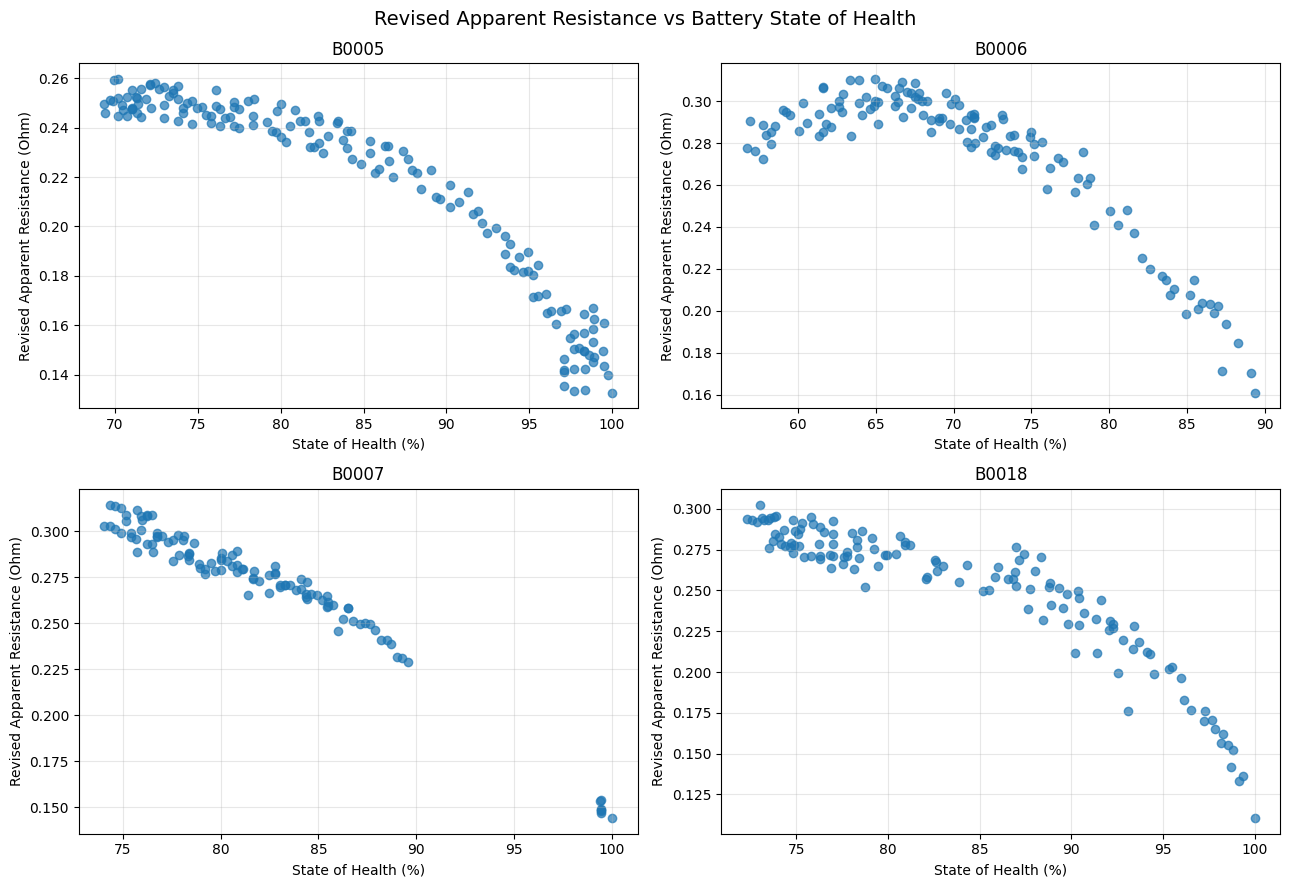


Files saved:
/content/drive/MyDrive/Battery_Digital_Twin/results/revised_resistance_vs_soh.png
/content/drive/MyDrive/Battery_Digital_Twin/results/revised_resistance_correlations.csv


In [51]:
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
import os

# Calculate correlations for each battery
correlation_results = []

for battery_id, group in revised_df.groupby("battery_id"):

    pearson_r, pearson_p = pearsonr(
        group["R_app_cutoff_ohm"],
        group["SoH_percent"]
    )

    spearman_r, spearman_p = spearmanr(
        group["R_app_cutoff_ohm"],
        group["SoH_percent"]
    )

    correlation_results.append({
        "battery_id": battery_id,
        "observations": len(group),
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_r": spearman_r,
        "Spearman_p": spearman_p
    })

correlation_df = pd.DataFrame(correlation_results)

print("=" * 65)
print("REVISED RESISTANCE–HEALTH CORRELATION")
print("=" * 65)

display(correlation_df.round(4))

# Plot resistance against SoH
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, (battery_id, group) in zip(
    axes, revised_df.groupby("battery_id")
):

    ax.scatter(
        group["SoH_percent"],
        group["R_app_cutoff_ohm"],
        alpha=0.7
    )

    ax.set_title(battery_id)
    ax.set_xlabel("State of Health (%)")
    ax.set_ylabel("Revised Apparent Resistance (Ohm)")
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Revised Apparent Resistance vs Battery State of Health",
    fontsize=14
)

plt.tight_layout()

plot_path = os.path.join(
    results_folder,
    "revised_resistance_vs_soh.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

# Export correlation results
correlation_path = os.path.join(
    results_folder,
    "revised_resistance_correlations.csv"
)

correlation_df.to_csv(correlation_path, index=False)

print("\nFiles saved:")
print(plot_path)
print(correlation_path)

In [52]:
from scipy.stats import pearsonr, spearmanr
from scipy.stats import linregress

trend_results = []

for battery_id, group in revised_df.groupby("battery_id"):

    group = group.sort_values("discharge_index").copy()

    # Remove the linear trend associated with discharge order
    resistance_trend = linregress(
        group["discharge_index"],
        group["R_app_cutoff_ohm"]
    )

    soh_trend = linregress(
        group["discharge_index"],
        group["SoH_percent"]
    )

    group["resistance_residual"] = (
        group["R_app_cutoff_ohm"]
        - resistance_trend.intercept
        - resistance_trend.slope * group["discharge_index"]
    )

    group["soh_residual"] = (
        group["SoH_percent"]
        - soh_trend.intercept
        - soh_trend.slope * group["discharge_index"]
    )

    # Correlation after removing linear ageing trends
    pearson_r, pearson_p = pearsonr(
        group["resistance_residual"],
        group["soh_residual"]
    )

    spearman_r, spearman_p = spearmanr(
        group["resistance_residual"],
        group["soh_residual"]
    )

    trend_results.append({
        "battery_id": battery_id,
        "observations": len(group),
        "Pearson_detrended": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_detrended": spearman_r,
        "Spearman_p": spearman_p
    })

trend_correlation_df = pd.DataFrame(trend_results)

print("=" * 65)
print("TREND-ADJUSTED RESISTANCE–HEALTH CORRELATION")
print("=" * 65)

display(trend_correlation_df.round(4))

# Save results
trend_path = os.path.join(
    results_folder,
    "trend_adjusted_resistance_correlations.csv"
)

trend_correlation_df.to_csv(trend_path, index=False)

print("\nResults saved to:")
print(trend_path)

TREND-ADJUSTED RESISTANCE–HEALTH CORRELATION


,battery_id,observations,Pearson_detrended,Pearson_p,Spearman_detrended,Spearman_p
0,B0005,161,-0.4426,0.0,-0.3689,0.0
1,B0006,131,-0.7489,0.0,-0.7729,0.0
2,B0007,109,-0.8389,0.0,-0.7914,0.0
3,B0018,132,-0.7455,0.0,-0.7478,0.0



Results saved to:
/content/drive/MyDrive/Battery_Digital_Twin/results/trend_adjusted_resistance_correlations.csv


In [53]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Merge revised resistance with the existing modelling dataset
resistance_features = revised_df[
    ["battery_id", "discharge_index", "R_app_cutoff_ohm"]
].copy()

comparison_df = model_dataset_C.merge(
    resistance_features,
    on=["battery_id", "discharge_index"],
    how="inner"
)

# Define the two models
baseline_features = [
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "current_mean",
    "temperature_mean",
    "temperature_max",
    "temperature_rise"
]

resistance_features_list = baseline_features + [
    "R_app_cutoff_ohm"
]

target = "SoH_percent"

# Keep identical observations for both models
required_columns = (
    baseline_features
    + ["R_app_cutoff_ohm", target, "battery_id"]
)

comparison_df = comparison_df.dropna(
    subset=required_columns
).copy()

results = []

# Leave-one-battery-out validation
for test_battery in sorted(comparison_df["battery_id"].unique()):

    train = comparison_df[
        comparison_df["battery_id"] != test_battery
    ]

    test = comparison_df[
        comparison_df["battery_id"] == test_battery
    ]

    model_results = {}

    for model_name, features in [
        ("Baseline", baseline_features),
        ("Baseline + Revised Resistance", resistance_features_list)
    ]:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=1.0))
        ])

        model.fit(train[features], train[target])
        predictions = model.predict(test[features])

        model_results[model_name] = {
            "MAE": mean_absolute_error(
                test[target], predictions
            ),
            "RMSE": np.sqrt(
                mean_squared_error(test[target], predictions)
            ),
            "R2": r2_score(test[target], predictions)
        }

    results.append({
        "battery_id": test_battery,
        "observations": len(test),
        "Baseline_MAE": model_results["Baseline"]["MAE"],
        "Resistance_MAE": model_results[
            "Baseline + Revised Resistance"
        ]["MAE"],
        "Baseline_RMSE": model_results["Baseline"]["RMSE"],
        "Resistance_RMSE": model_results[
            "Baseline + Revised Resistance"
        ]["RMSE"],
        "Baseline_R2": model_results["Baseline"]["R2"],
        "Resistance_R2": model_results[
            "Baseline + Revised Resistance"
        ]["R2"]
    })

results_df = pd.DataFrame(results)

# Weighted overall performance
total_observations = results_df["observations"].sum()

baseline_mae = np.average(
    results_df["Baseline_MAE"],
    weights=results_df["observations"]
)

resistance_mae = np.average(
    results_df["Resistance_MAE"],
    weights=results_df["observations"]
)

baseline_rmse = np.sqrt(np.average(
    results_df["Baseline_RMSE"] ** 2,
    weights=results_df["observations"]
))

resistance_rmse = np.sqrt(np.average(
    results_df["Resistance_RMSE"] ** 2,
    weights=results_df["observations"]
))

improvement = (
    (baseline_mae - resistance_mae) / baseline_mae
) * 100

print("=" * 70)
print("BASELINE VS REVISED RESISTANCE MODEL")
print("=" * 70)

print("\nObservations used:", total_observations)

display(results_df.round(4))

print("\nWEIGHTED OVERALL PERFORMANCE")
print("Baseline MAE:", round(baseline_mae, 4))
print("Resistance model MAE:", round(resistance_mae, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))
print("Resistance model RMSE:", round(resistance_rmse, 4))
print("MAE improvement (%):", round(improvement, 2))

BASELINE VS REVISED RESISTANCE MODEL

Observations used: 533


,battery_id,observations,Baseline_MAE,Resistance_MAE,Baseline_RMSE,Resistance_RMSE,Baseline_R2,Resistance_R2
0,B0005,161,1.6197,1.2225,2.1150,1.7690,0.9561,0.9693
1,B0006,131,3.7047,3.7285,4.2405,4.2253,0.7495,0.7513
2,B0007,109,1.4191,1.5286,2.4234,2.0801,0.8454,0.8861
3,B0018,132,1.0392,3.4122,1.2456,3.7339,0.9776,0.7985



WEIGHTED OVERALL PERFORMANCE
Baseline MAE: 1.9474
Resistance model MAE: 2.4433
Baseline RMSE: 2.7122
Resistance model RMSE: 3.1098
MAE improvement (%): -25.47


In [54]:
# Save revised resistance model comparison

comparison_results_path = os.path.join(
    results_folder,
    "revised_resistance_model_comparison.csv"
)

results_df.to_csv(comparison_results_path, index=False)

# Create a summary of the overall results
resistance_model_summary = pd.DataFrame({
    "Model": [
        "Baseline",
        "Baseline + Revised Apparent Resistance"
    ],
    "Weighted_MAE": [
        baseline_mae,
        resistance_mae
    ],
    "Weighted_RMSE": [
        baseline_rmse,
        resistance_rmse
    ]
})

summary_path = os.path.join(
    results_folder,
    "revised_resistance_model_summary.csv"
)

resistance_model_summary.to_csv(summary_path, index=False)

print("Model comparison successfully saved.")
print(comparison_results_path)
print(summary_path)

display(resistance_model_summary.round(4))

Model comparison successfully saved.
/content/drive/MyDrive/Battery_Digital_Twin/results/revised_resistance_model_comparison.csv
/content/drive/MyDrive/Battery_Digital_Twin/results/revised_resistance_model_summary.csv


,Model,Weighted_MAE,Weighted_RMSE
0,Baseline,1.9474,2.7122
1,Baseline + Revised Apparent Resistance,2.4433,3.1098


In [55]:
# Append revised resistance findings to the modelling summary

summary_path = os.path.join(
    results_folder,
    "modelling_summary.md"
)

new_section = """

## 14. Revised Apparent Resistance Estimation

An apparent resistance proxy was estimated using the fitted
post-discharge relaxation amplitude and the absolute discharge
current immediately before cutoff:

R_app_cutoff = A / I_before_cutoff

This quantity is treated as an apparent resistance indicator,
not as a directly measured ohmic resistance.

The revised estimates were:

| Battery | Mean apparent resistance (Ohm) |
|---|---:|
| B0005 | 0.2166 |
| B0006 | 0.2747 |
| B0007 | 0.2708 |
| B0018 | 0.2504 |

A total of 533 observations were available, with no missing,
duplicate, zero, or negative resistance values.

## 15. Revised Resistance and State of Health

The revised apparent resistance showed a strong negative
correlation with SoH:

| Battery | Pearson r | Spearman r |
|---|---:|---:|
| B0005 | -0.9299 | -0.9419 |
| B0006 | -0.8322 | -0.7140 |
| B0007 | -0.9680 | -0.9701 |
| B0018 | -0.9035 | -0.9287 |

After removing the linear trend associated with discharge
index, negative correlations remained:

| Battery | Detrended Pearson r | Detrended Spearman r |
|---|---:|---:|
| B0005 | -0.4426 | -0.3689 |
| B0006 | -0.7489 | -0.7729 |
| B0007 | -0.8389 | -0.7914 |
| B0018 | -0.7455 | -0.7478 |

These results indicate that the resistance–SoH association
is not explained entirely by a shared linear ageing trend.
However, correlation does not establish causality or validate
the proxy as a direct physical resistance measurement.

## 16. Predictive Evaluation of Revised Apparent Resistance

A leave-one-battery-out comparison was performed using the
same 533 observations for both models.

The baseline model used voltage, current, and temperature
features. The augmented model additionally included revised
apparent resistance.

| Model | Weighted MAE | Weighted RMSE |
|---|---:|---:|
| Baseline | 1.9474 | 2.7122 |
| Baseline + revised apparent resistance | 2.4433 | 3.1098 |

Adding revised apparent resistance increased weighted MAE
by 25.47% and weighted RMSE by approximately 14.66%.

The effect varied across batteries. Performance improved
for B0005, changed only slightly for B0006, and deteriorated
for B0007 and particularly B0018 in terms of MAE.

Therefore, revised apparent resistance is retained as a
diagnostic degradation indicator, but it is not selected
as an additional feature in the current cross-battery
predictive model.

## 17. Updated Interpretation and Limitations

The revised resistance experiment provides evidence of a
strong association between an apparent relaxation-derived
resistance indicator and battery health.

However, its predictive contribution does not generalise
consistently across the four batteries.

The current estimate is based on relaxation amplitude
divided by current immediately before discharge cutoff.
It is not an independently validated measurement of
instantaneous ohmic resistance.

Further validation would require more detailed electrical
measurements and a physically identifiable equivalent
circuit model.

The current baseline model remains the preferred
cross-battery predictive model based on the evaluated
weighted MAE and RMSE.
"""

with open(summary_path, "a", encoding="utf-8") as file:
    file.write(new_section)

print("Modelling summary updated successfully.")
print("Updated file:", summary_path)

Modelling summary updated successfully.
Updated file: /content/drive/MyDrive/Battery_Digital_Twin/results/modelling_summary.md


In [56]:
import os

project_folder = "/content/drive/MyDrive/Battery_Digital_Twin"

folders_to_check = [
    "raw_data",
    "notebooks",
    "results"
]

print("=" * 65)
print("BATTERY DIGITAL TWIN — PROJECT FILE AUDIT")
print("=" * 65)

for folder in folders_to_check:

    folder_path = os.path.join(project_folder, folder)

    print(f"\n{folder.upper()}")

    if os.path.exists(folder_path):

        files = sorted(os.listdir(folder_path))

        for filename in files:
            full_path = os.path.join(folder_path, filename)

            if os.path.isfile(full_path):
                size_mb = os.path.getsize(full_path) / (1024 * 1024)
                print(f"  {filename} ({size_mb:.2f} MB)")
            else:
                print(f"  {filename}/")

    else:
        print("  Folder not found!")

print("\nPROJECT ROOT")

for filename in sorted(os.listdir(project_folder)):
    full_path = os.path.join(project_folder, filename)

    if os.path.isfile(full_path):
        size_mb = os.path.getsize(full_path) / (1024 * 1024)
        print(f"  {filename} ({size_mb:.2f} MB)")

print("\nAudit completed.")

BATTERY DIGITAL TWIN — PROJECT FILE AUDIT

RAW_DATA
  B0005.mat (15.22 MB)
  B0006.mat (15.29 MB)
  B0007.mat (15.31 MB)
  B0018.mat (8.11 MB)

NOTEBOOKS
  02_Battery_Digital_Twin_Architecture.ipynb (2.55 MB)

RESULTS
  apparent_RC_parameters.csv (0.26 MB)
  combined_battery_dataset.csv (0.18 MB)
  combined_dataset_with_relaxation.csv (0.23 MB)
  cycle_Re_correlations.csv (0.00 MB)
  full_data_coefficients.csv (0.00 MB)
  hybrid_predictions.csv (0.04 MB)
  hybrid_soh_residuals.png (0.67 MB)
  hybrid_soh_validation.png (0.94 MB)
  impedance_contribution_analysis.csv (0.00 MB)
  lobo_relaxation_model_comparison.csv (0.00 MB)
  lobo_relaxation_overall_results.csv (0.00 MB)
  model_A_vs_hybrid.csv (0.00 MB)
  modelling_summary.md (0.01 MB)
  multicollinearity_VIF.csv (0.00 MB)
  overall_model_performance.csv (0.00 MB)
  relaxation_parameters_all_batteries.csv (0.05 MB)
  relaxation_soh_correlations_all_batteries.csv (0.00 MB)
  residual_Re_comparison.csv (0.00 MB)
  residual_statistics.csv

In [57]:
import nbformat
import os

notebooks = [
    os.path.join(
        project_folder,
        "01_Battery_Digital_Twin_Data_Exploration_and_Modelling.ipynb"
    ),
    os.path.join(
        project_folder,
        "notebooks",
        "02_Battery_Digital_Twin_Architecture.ipynb"
    )
]

print("=" * 65)
print("NOTEBOOK QUALITY INSPECTION")
print("=" * 65)

for notebook_path in notebooks:

    notebook = nbformat.read(notebook_path, as_version=4)

    code_cells = [
        cell for cell in notebook.cells
        if cell.cell_type == "code"
    ]

    markdown_cells = [
        cell for cell in notebook.cells
        if cell.cell_type == "markdown"
    ]

    cells_with_outputs = [
        cell for cell in code_cells
        if len(cell.get("outputs", [])) > 0
    ]

    print("\nNotebook:", os.path.basename(notebook_path))
    print("Total cells:", len(notebook.cells))
    print("Code cells:", len(code_cells))
    print("Markdown cells:", len(markdown_cells))
    print("Cells with outputs:", len(cells_with_outputs))
    print(
        "Executed code cells:",
        sum(cell.get("execution_count") is not None
            for cell in code_cells)
    )

    print(
        "File size (MB):",
        round(os.path.getsize(notebook_path) / (1024 * 1024), 2)
    )

print("\nInspection completed.")

NOTEBOOK QUALITY INSPECTION

Notebook: 01_Battery_Digital_Twin_Data_Exploration_and_Modelling.ipynb
Total cells: 154
Code cells: 153
Markdown cells: 1
Cells with outputs: 149
Executed code cells: 153
File size (MB): 3.47

Notebook: 02_Battery_Digital_Twin_Architecture.ipynb
Total cells: 62
Code cells: 61
Markdown cells: 1
Cells with outputs: 61
Executed code cells: 61
File size (MB): 2.55

Inspection completed.


In [58]:
import os
import nbformat

# Create GitHub preparation folders
github_folder = os.path.join(project_folder, "github_ready")
github_notebooks_folder = os.path.join(github_folder, "notebooks")

os.makedirs(github_notebooks_folder, exist_ok=True)

notebooks_to_prepare = [
    os.path.join(
        project_folder,
        "01_Battery_Digital_Twin_Data_Exploration_and_Modelling.ipynb"
    ),
    os.path.join(
        project_folder,
        "notebooks",
        "02_Battery_Digital_Twin_Architecture.ipynb"
    )
]

print("=" * 65)
print("PREPARING CLEAN GITHUB NOTEBOOKS")
print("=" * 65)

for original_path in notebooks_to_prepare:

    notebook = nbformat.read(original_path, as_version=4)

    # Remove saved outputs without changing the code
    for cell in notebook.cells:

        if cell.cell_type == "code":
            cell.outputs = []
            cell.execution_count = None

    # Preserve the original notebook name
    output_path = os.path.join(
        github_notebooks_folder,
        os.path.basename(original_path)
    )

    nbformat.write(notebook, output_path)

    print("\nCreated:", os.path.basename(output_path))
    print("Code cells:", sum(
        cell.cell_type == "code" for cell in notebook.cells
    ))
    print("Saved outputs:", sum(
        len(cell.get("outputs", []))
        for cell in notebook.cells
        if cell.cell_type == "code"
    ))

print("\nClean GitHub notebook copies created.")
print("Location:", github_notebooks_folder)

PREPARING CLEAN GITHUB NOTEBOOKS

Created: 01_Battery_Digital_Twin_Data_Exploration_and_Modelling.ipynb
Code cells: 153
Saved outputs: 0

Created: 02_Battery_Digital_Twin_Architecture.ipynb
Code cells: 61
Saved outputs: 0

Clean GitHub notebook copies created.
Location: /content/drive/MyDrive/Battery_Digital_Twin/github_ready/notebooks


In [59]:
import nbformat
import os

notebook_path = os.path.join(
    project_folder,
    "github_ready",
    "notebooks",
    "02_Battery_Digital_Twin_Architecture.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

print("=" * 65)
print("ARCHITECTURE NOTEBOOK — CONTENT REVIEW")
print("=" * 65)

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code":
        lines = [
            line.strip()
            for line in cell.source.splitlines()
            if line.strip()
        ]

        preview = " | ".join(lines[:2])
        print(f"\nCell {i}: {preview[:180]}")

print("\nReview completed.")

ARCHITECTURE NOTEBOOK — CONTENT REVIEW

Cell 1: # Battery Digital Twin – Architecture | import os

Cell 2: # Load and validate the combined battery dataset | data_path = os.path.join(

Cell 3: from dataclasses import dataclass | from typing import Optional

Cell 4: def update_battery_state(state, observation): | # Update battery identification

Cell 5: # Test the Digital Twin state update | first_observation = combined_df.iloc[0]

Cell 6: from dataclasses import asdict | # Select the first five observations of B0005

Cell 7: # Build the complete digital state history for B0005 | # Select all observations for B0005

Cell 8: # Machine-learning imports | from sklearn.pipeline import Pipeline

Cell 9: # Step 16: Train the first SoH estimation model | # 1. Define the input features

Cell 10: # Connect machine-learning predictions to the Digital Twin | # Generate SoH estimates for all B0005 observations

Cell 11: # Compare measured and estimated State of Health | plt.figure(figsize=(12, 6))


In [60]:
import nbformat
import os

notebook_path = os.path.join(
    project_folder,
    "github_ready",
    "notebooks",
    "02_Battery_Digital_Twin_Architecture.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

print("=" * 65)
print("INTRODUCTION AND DIGITAL TWIN ARCHITECTURE REVIEW")
print("=" * 65)

for i in range(10):

    cell = nb.cells[i]

    print(f"\n{'=' * 25} CELL {i} {'=' * 25}")
    print("Type:", cell.cell_type)
    print(cell.source[:2500])

print("\nInspection completed.")

INTRODUCTION AND DIGITAL TWIN ARCHITECTURE REVIEW

========================= CELL 0 =========================
Type: markdown
# Battery Digital Twin Architecture and State-of-Health Modelling

## Project Overview

This notebook presents the development of a prototype Digital Twin framework for lithium-ion battery health monitoring, based on experimental battery ageing data from the NASA Battery Aging dataset.

The project investigates how experimental battery measurements, degradation-related indicators, and machine-learning models can be integrated into a structured digital representation of a physical battery. The proposed framework maintains an updated digital battery state as new observations become available and uses this information to support State-of-Health (SoH) estimation and degradation analysis.

The primary focus is on developing and evaluating a data-driven battery monitoring architecture, with particular attention to cross-battery model generalisation, impedance-related i

In [61]:
import nbformat
import os

notebook_path = os.path.join(
    project_folder,
    "github_ready",
    "notebooks",
    "02_Battery_Digital_Twin_Architecture.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

print("=" * 65)
print("MACHINE LEARNING SECTION REVIEW")
print("=" * 65)

for i in range(9, 18):
    cell = nb.cells[i]

    print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
    print("Type:", cell.cell_type)
    print(cell.source[:3000])

MACHINE LEARNING SECTION REVIEW

==================== CELL 9 ====================
Type: code

# Step 16: Train the first SoH estimation model

# 1. Define the input features
features_A = [
    "voltage_mean",
    "voltage_min",
    "voltage_max",
    "current_mean",
    "temperature_mean",
    "temperature_max",
    "temperature_rise"
]

target = "SoH_percent"

# 2. Split the data: train on three batteries, test on B0005
train_data = combined_df[
    combined_df["battery_id"] != "B0005"
].copy()

test_data = combined_df[
    combined_df["battery_id"] == "B0005"
].copy()

X_train = train_data[features_A]
y_train = train_data[target]

X_test = test_data[features_A]
y_test = test_data[target]

# 3. Define the machine-learning pipeline
soh_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

# 4. Train the model
soh_model.fit(X_train, y_train)

# 5. Estimate SoH for B0005
predictions = soh_model.predict(X_test)

# 6. Evaluate the predictions
mae = mean_a